In [ ]:
# Locate the organized checkout and use its preserved execution layout.
from pathlib import Path
import os, runpy, sys
_bases = [Path.cwd(), *Path.cwd().parents]
_part2 = next(candidate for base in _bases for candidate in (base, base / "part2")
              if (candidate / "run.py").is_file() and (candidate / "layout.json").is_file())
_workspace = runpy.run_path(str(_part2 / "run.py"))["prepare_workspace"]()
os.chdir(_workspace)
sys.path.insert(0, str(_workspace))


# Extending Ani's outcome stack

**File 10 Kaggle result: 0.58609 (user-reported).** File 09's Kaggle score is unknown. The current ledger records results reported after the frozen export manifests. Local chronological intervals include zero. Training code is embedded below; default execution reads the saved results.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
if (root / 'part2').exists(): root /= 'part2'
out = root / 'experiments/ani_extensions'
decision = out / 'decision'
display(json.loads((decision / 'selection.json').read_text()))

{'shortlist': [{'model': 'replace_knn5',
   'batch': 'neighbors',
   'recipe': {'bank': 'recent',
    'tau': 3.0,
    'trend': False,
    'C': 1.0,
    'replace': 5}},
  {'model': 'fast2_neighbors_half',
   'batch': 'neighbors',
   'recipe': {'blend': {'ani_stack': 0.5, 'fast2_neighbors': 0.5}}}],
 'source_runs': {'meta': 'experiments/ani_extensions/meta/76d98f1d5e9d5ff1',
  'neighbors': 'experiments/ani_extensions/neighbors/a27759052dfa9571'},
 'input_hashes': {'meta/strict': '6507d190a9eb2647d0c39bb02cb5cdabb0391572064a218c8f65d210f7a2f005',
  'meta/published': '9e1cf364b19b9135444463625f9031ba7955db9e17110cd9fd73dff00b0117de',
  'neighbors/strict': 'ef32094823a1c4570770525fde51b7e3775a19d275ba9fc2e2d6b5010ea770f4',
  'neighbors/published': 'ea5bef97ffd980a355e0abb029c8ad945404ed9443154d0fc2a5b686d8fe57ca'},
 'policy_sha256': 'beedd6d47c8586444eca564e17c9e1219aa1ff663482944220db04365a57a72b',
 'status': 'Frozen before candidate predictions on gapped windows and final fitting'}

strict


,model,completed_splits,official,temporal,worst,cv
0,ani_first,10,0.557370,0.542145,0.590898,0.579653
1,ani_phase3_trend,10,0.556030,0.537131,0.588951,0.586468
2,ani_stack,10,0.555039,0.537446,0.588574,0.587411
3,fast2_neighbors_half,10,0.557839,0.535890,0.587101,0.586891
4,replace_knn5,10,0.560796,0.535213,0.586014,0.589230


Larger time gaps


,model,completed_splits,official,temporal,worst,cv
0,ani_first,3,NaN,0.568041,0.633776,NaN
1,ani_phase3_trend,3,NaN,0.562422,0.627050,NaN
2,ani_stack,3,NaN,0.564681,0.630298,NaN
3,fast2_neighbors_half,3,NaN,0.563189,0.628816,NaN
4,replace_knn5,3,NaN,0.563657,0.630312,NaN


published


,model,completed_splits,official,temporal,worst,cv
0,ani_first,10,0.558898,0.540625,0.588684,0.577507
1,ani_phase3_trend,10,0.557150,0.535460,0.587985,0.584607
2,ani_stack,10,0.556108,0.535751,0.587659,0.585465
3,fast2_neighbors_half,10,0.559173,0.534547,0.586828,0.585453
4,replace_knn5,10,0.561697,0.533687,0.586055,0.587178


Larger time gaps


,model,completed_splits,official,temporal,worst,cv
0,ani_first,3,NaN,0.568040,0.633129,NaN
1,ani_phase3_trend,3,NaN,0.561546,0.625192,NaN
2,ani_stack,3,NaN,0.563803,0.628274,NaN
3,fast2_neighbors_half,3,NaN,0.562306,0.626429,NaN
4,replace_knn5,3,NaN,0.562923,0.628877,NaN


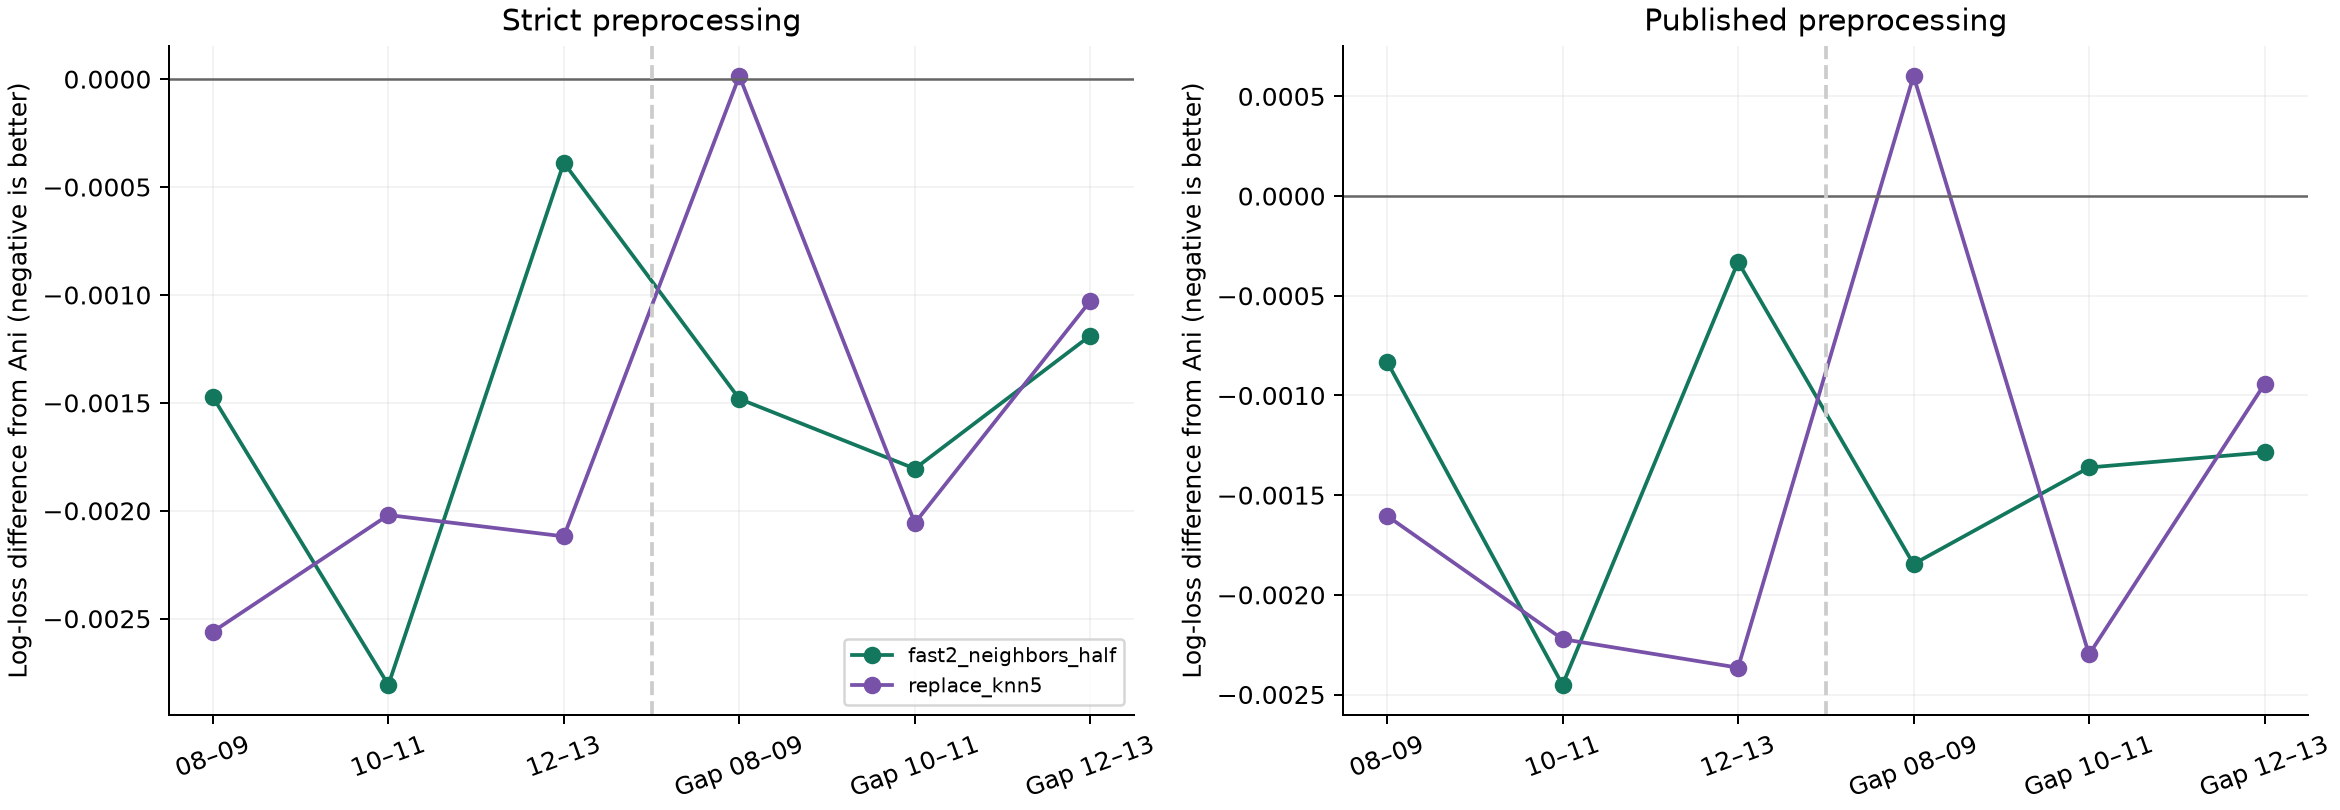

In [2]:
for track in ['strict','published']:
    print(track)
    display(pd.read_csv(decision / track / 'summary.csv').round(6))
    print('Larger time gaps')
    display(pd.read_csv(decision / 'gaps' / track / 'summary.csv').round(6))
display(Image(filename=str(decision / 'figures/chronological_differences.png')))

In [3]:
pairs=pd.read_csv(decision / 'paired_comparisons.csv')
display(pairs[(pairs.track=='strict') & (pairs.reference=='ani_stack')].round(6))
display(pd.read_csv(decision / 'phase_metrics.csv').round(6))
display(pd.read_csv(decision / 'reason_errors.csv').round(4))
display(json.loads((decision / 'verification.json').read_text()))
display(json.loads((decision / 'final_manifest.json').read_text()))

,track,model,reference,kind,delta,lower,upper,trials,bootstrap_repetitions
0,strict,replace_knn5,ani_stack,temporal,-0.002233,-0.005094,0.000547,3478,2000
1,strict,replace_knn5,ani_stack,group_cv,0.001819,0.000202,0.003439,8436,2000
6,strict,fast2_neighbors_half,ani_stack,temporal,-0.001556,-0.003842,0.000791,3478,2000
7,strict,fast2_neighbors_half,ani_stack,group_cv,-0.000520,-0.001642,0.000661,8436,2000


,track,model,phase,logloss,f1,roc_auc,pr_auc
0,strict,ani_stack,I,0.555754,0.792899,0.793750,0.829987
1,strict,ani_stack,II,0.592863,0.646925,0.753486,0.732118
2,strict,ani_stack,III,0.516499,0.824859,0.789804,0.881745
3,strict,ani_first,I,0.567686,0.752809,0.775184,0.820039
4,strict,ani_first,II,0.590758,0.668122,0.749984,0.732612
5,strict,ani_first,III,0.513665,0.821293,0.789634,0.883276
6,strict,ani_phase3_trend,I,0.556048,0.792899,0.793750,0.830206
7,strict,ani_phase3_trend,II,0.592600,0.646925,0.753406,0.732002
8,strict,ani_phase3_trend,III,0.519442,0.820809,0.787161,0.880021
9,strict,replace_knn5,I,0.564009,0.790960,0.783824,0.821061


,phase,reason,n,false_success,false_success_rate,wilson_lower,wilson_upper,true_reason_rows,predicted_reason_rows,track,model
0,I,Safety,9,3,0.3333,0.1206,0.6458,1,8,strict,ani_stack
1,I,Funding,4,0,0.0000,0.0000,0.4899,1,3,strict,ani_stack
2,I,Efficacy,2,2,1.0000,0.3424,1.0000,0,2,strict,ani_stack
3,I,Recruitment,22,2,0.0909,0.0253,0.2782,2,20,strict,ani_stack
4,I,Other,5,2,0.4000,0.1176,0.7693,0,5,strict,ani_stack
...,...,...,...,...,...,...,...,...,...,...,...
175,III,Funding,0,0,NaN,NaN,NaN,0,0,published,fast2_neighbors_half
176,III,Efficacy,9,9,1.0000,0.7008,1.0000,0,9,published,fast2_neighbors_half
177,III,Recruitment,21,11,0.5238,0.3237,0.7166,5,16,published,fast2_neighbors_half
178,III,Other,8,5,0.6250,0.3057,0.8632,2,6,published,fast2_neighbors_half


{'extension_recipes': 40,
 'new_recipe_evaluations': 800,
 'original_splits_per_track': 10,
 'preprocessing_tracks': 2,
 'controls_reproduce': True,
 'source_and_input_hashes_match': True,
 'grouped_inner_preprocessing_verified': True,
 'independently_rescored': True,
 'gapped_splits_per_track': 3,
 'exported_submissions': 2,
 'native_replay_max_error': 0.0,
 'labels_and_identifiers_do_not_change_inference': True,
 'kaggle_scores_unknown': False,
 'reported_kaggle_scores': {'09_ani_replace_knn5.csv': None,
  '10_ani_fast2_neighbors_half.csv': 0.58609},
 'leaderboard_sha256': '11013051532d3a114967243917e93edb3d7085bce99b7ff13b1a45d88597cd0c'}

{'submissions': [{'file': '09_ani_replace_knn5.csv',
   'model': 'replace_knn5',
   'sha256': '2aef6030c184ea3dbb0fa271519e2330d61bb9853bd7c63b2baab8f18f9ea75d',
   'kaggle_score': None,
   'training_rows': 9050,
   'recipe': {'model': 'replace_knn5',
    'batch': 'neighbors',
    'recipe': {'bank': 'recent',
     'tau': 3.0,
     'trend': False,
     'C': 1.0,
     'replace': 5}},
   'gapped_deltas': {'strict': -0.0010234036473946162,
    'published': -0.0008798786272197212},
   'status': 'Corroborated locally; Kaggle untested'},
  {'file': '10_ani_fast2_neighbors_half.csv',
   'model': 'fast2_neighbors_half',
   'sha256': 'd6fa9e347cbb670d3c190b2cf387dcdd06d42d92930bae8abc35974e2b648448',
   'kaggle_score': None,
   'training_rows': 9050,
   'recipe': {'model': 'fast2_neighbors_half',
    'batch': 'neighbors',
    'recipe': {'blend': {'ani_stack': 0.5, 'fast2_neighbors': 0.5}}},
   'gapped_deltas': {'strict': -0.001491671723966026,
    'published': -0.001497586645009874},
   'status'

## Full implementation source

The source bundle below includes the estimators, feature extraction, benchmark orchestration, inference and verification code. It is stored as strings so normal execution does not launch training. The repository supplies CSVs, frozen splits and source-checksummed previous OOF arrays. No external labeled data is retrieved.

In [4]:
SOURCES = {}

In [5]:
# ani_models.py
SOURCES['ani_models.py'] = r'''"""Ani's eight-model stack, made reusable for fold-local evaluation.

Adapted from Ani's midterm/part2_best_model.ipynb at commit
1b8bd11c47428fb5453e53cdc275542b92a3b347. The preserved source is in
experiments/ani_comparison/source/. Transductive reproduction passes an
explicit feature space fitted on all available covariates; the benchmark
defaults to fitting its vocabulary and IDF only on the fold's training rows.
"""
from __future__ import annotations
import ast
import numpy as np
import pandas as pd
from scipy import sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer,CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import normalize

PHASES=('I','II','III')
BASES=[('criteria LR',['criteria'],2.),('disease LR',['disease'],1.),
       ('ICD LR',['icd'],1.),('drug-name LR',['drug'],1.),
       ('drug-knowledge LR',['targets','pathways','actions'],.3),
       ('metadata LR',['meta'],1.),('criteria MNB',['crit_counts'],None),
       ('criteria kNN',['criteria'],None)]


def parse_list(s):
    try:
        out=[]
        for x in ast.literal_eval(s):
            out+=ast.literal_eval(x) if isinstance(x,str) and x.startswith('[') else [x]
        return [str(x) for x in out]
    except (ValueError,SyntaxError):return []


def text_fields(df):
    icd=df.icdcodes.fillna('[]').map(parse_list)
    text={'criteria':df.criteria.fillna(''),
          'disease':df.diseases_cleaned.fillna('[]').map(lambda s:' '.join(parse_list(s))),
          'drug':df.drugs.fillna('[]').map(lambda s:' '.join(parse_list(s))),
          'icd':icd.map(lambda v:' '.join(sorted({c[:1] for c in v}|{c[:3] for c in v}|{c[:5] for c in v})))}
    for key,col in [('targets','drug_targets'),('pathways','drug_pathways'),('actions','drug_actions')]:
        text[key]=df[col].fillna('').map(lambda s:' '.join(sorted({t.strip() for t in s.split(';') if t.strip()})))
    return text


def onehot(df):return np.column_stack([df.phase.eq(p).to_numpy().astype(float) for p in PHASES])


class AniFeatures:
    def fit(self,df):
        text=text_fields(df);split=dict(tokenizer=str.split,lowercase=False,token_pattern=None)
        self.vectorizers={
            'criteria':TfidfVectorizer(min_df=5,ngram_range=(1,2),sublinear_tf=True),
            'crit_counts':CountVectorizer(min_df=5,ngram_range=(1,2)),
            'disease':TfidfVectorizer(min_df=2,ngram_range=(1,2),sublinear_tf=True),
            'drug':TfidfVectorizer(min_df=2,sublinear_tf=True),
            'icd':TfidfVectorizer(min_df=2,**split),'targets':TfidfVectorizer(min_df=3,**split),
            'pathways':TfidfVectorizer(min_df=5,**split),'actions':CountVectorizer(min_df=2,binary=True,**split)}
        for key,vec in self.vectorizers.items():vec.fit(text['criteria' if key=='crit_counts' else key])
        self.year_median=float(df.start_year.median())
        self.fit_ids=df.ID.tolist()
        return self

    def transform(self,df):
        text=text_fields(df)
        f={key:vec.transform(text['criteria' if key=='crit_counts' else key]) for key,vec in self.vectorizers.items()}
        f['meta']=sp.csr_matrix(np.column_stack([
            df.matched_drugs.notna(),np.log1p(text['drug'].str.split().str.len()),
            np.log1p(text['criteria'].str.len())/10,df.phase_detail.str.contains('/'),
            df.phase_detail.eq('early phase 1')]).astype(float))
        f['phase']=sp.csr_matrix(onehot(df));f['knn']=normalize(f['criteria'])
        return f


def matrix(f,blocks):return sp.hstack([f[k] for k in blocks]+[f['phase']],format='csr')


def fit_base(name,blocks,C,f,df,weights):
    if name=='criteria kNN':
        # Faithfully preserve Ani's implementation: recency does not weight kNN.
        return {p:(f['knn'][df.phase.eq(p).to_numpy()],df.label.to_numpy()[df.phase.eq(p).to_numpy()]) for p in PHASES}
    x=matrix(f,blocks)
    model=MultinomialNB(alpha=1.) if name=='criteria MNB' else LogisticRegression(C=C,max_iter=3000)
    return model.fit(x,df.label.to_numpy(),sample_weight=weights)


def predict_base(name,blocks,model,f,df,k=50):
    if name!='criteria kNN':return model.predict_proba(matrix(f,blocks))[:,1]
    result=np.zeros(len(df))
    for phase,(x,y) in model.items():
        mask=df.phase.eq(phase).to_numpy()
        if not mask.any():continue
        similarities=(f['knn'][mask]@x.T).toarray()
        neighbors=min(k,len(y)-1)
        idx=np.argpartition(-similarities,neighbors,axis=1)[:,:neighbors]
        weights=np.take_along_axis(similarities,idx,1)
        result[mask]=((weights*y[idx]).sum(axis=1)+1)/(weights.sum(axis=1)+2)
    return result


def subset(f,idx):return {k:v[idx] for k,v in f.items()}


class AniStack:
    def __init__(self,tau=3.,meta_C=1.,phase3_year=False,knn_k=50,inner_refit=False):
        self.tau=tau;self.meta_C=meta_C;self.phase3_year=phase3_year;self.knn_k=knn_k;self.inner_refit=inner_refit

    def meta_matrix(self,z,df):
        p=np.clip(z,1e-4,1-1e-4);ph=onehot(df)
        parts=[np.log(p/(1-p)),ph]
        if self.phase3_year:
            year=df.start_year.fillna(self.features.year_median).to_numpy()
            parts.append((ph[:,2]*(np.minimum(year,self.year_cap)-2007)/3)[:,None])
        return np.hstack(parts)

    def fit(self,df,features=None):
        df=df.reset_index(drop=True)
        self.features=features if features is not None else AniFeatures().fit(df)
        f=self.features.transform(df);year=df.start_year.fillna(self.features.year_median).to_numpy()
        self.year_cap=float(year.max()+2)
        w=np.ones(len(df)) if self.tau is None else np.exp((year-year.max())/self.tau)
        w=w/w.mean();z=np.zeros((len(df),len(BASES)));self.models=[];self.fold_audit=[]
        folds=list(GroupKFold(5).split(np.arange(len(df)),groups=df.trial_id.to_numpy()))
        if self.inner_refit:
            for fold,(a,b) in enumerate(folds):
                assert not set(df.trial_id.iloc[a])&set(df.trial_id.iloc[b])
                inner=AniFeatures().fit(df.iloc[a])
                fa,fb=inner.transform(df.iloc[a]),inner.transform(df.iloc[b])
                for j,(name,blocks,C) in enumerate(BASES):
                    m=fit_base(name,blocks,C,fa,df.iloc[a],w[a])
                    z[b,j]=predict_base(name,blocks,m,fb,df.iloc[b],self.knn_k)
                self.fold_audit.append({'fold':fold,'fit_rows':len(a),'heldout_rows':len(b),'trial_overlap':0,'preprocessing':'inner training rows only'})
            self.models=[fit_base(name,blocks,C,f,df,w) for name,blocks,C in BASES]
        else:
            for j,(name,blocks,C) in enumerate(BASES):
                for fold,(a,b) in enumerate(folds):
                    assert not set(df.trial_id.iloc[a])&set(df.trial_id.iloc[b])
                    m=fit_base(name,blocks,C,subset(f,a),df.iloc[a],w[a])
                    z[b,j]=predict_base(name,blocks,m,subset(f,b),df.iloc[b],self.knn_k)
                    if j==0:self.fold_audit.append({'fold':fold,'fit_rows':len(a),'heldout_rows':len(b),'trial_overlap':0,'preprocessing':'shared fitting-population vocabulary'})
                self.models.append(fit_base(name,blocks,C,f,df,w))
        self.meta=LogisticRegression(C=self.meta_C,max_iter=3000).fit(self.meta_matrix(z,df),df.label.to_numpy(),sample_weight=w)
        self.oof_base_predictions=z;self.training_ids=df.ID.tolist()
        return self

    def predict_base_matrix(self,df):
        f=self.features.transform(df)
        return np.column_stack([predict_base(name,blocks,m,f,df,self.knn_k) for (name,blocks,_),m in zip(BASES,self.models)])

    def predict_proba(self,df):return self.meta.predict_proba(self.meta_matrix(self.predict_base_matrix(df),df))[:,1]
'''

In [6]:
# experiments.py
SOURCES['experiments.py'] = r'''"""Reproducible Part 2 experiments. Only supplied pre-outcome features are used.

Run from any directory: ../../.venv/bin/python experiments.py --stage screen
All preprocessing is refitted on each experiment's fitting population.
"""
from __future__ import annotations

import argparse
import ast
import hashlib
import json
import os
import re
import time
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")

import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, log_loss, roc_auc_score
from sklearn.preprocessing import normalize

ROOT = Path(__file__).resolve().parent
OUT = ROOT / "experiments" / "model_search"
OUT.mkdir(parents=True, exist_ok=True)
PHASES = ("I", "II", "III")
REASONS = ["Safety", "Funding", "Efficacy", "Recruitment", "Other"]


def load_data():
    return {s: pd.read_csv(ROOT / f"outcome_{s}.csv") for s in ("train", "val", "test")}


def audit_data(data=None):
    data=load_data() if data is None else data
    audit={'datasets':{},'overlaps':{},
        'excluded_predictors':['ID','trial_id','label','all Part 1 reason labels and embeddings'],
        'evaluation':'Equal mean of per-phase log losses; official validation and train-only chronological holdout at 2008'}
    for split,df in data.items():
        assert not df.ID.duplicated().any()
        if 'label' in df:
            assert set(df.label)=={0,1}
            assert df.groupby('trial_id').label.nunique().max()==1
        audit['datasets'][split]={'rows':len(df),'trials':df.trial_id.nunique(),
            'min_year':float(df.start_year.min()),'max_year':float(df.start_year.max()),
            'sha256':hashlib.sha256((ROOT/f'outcome_{split}.csv').read_bytes()).hexdigest(),
            'phases':df.phase.value_counts().to_dict(),
            'matched_drug_fraction':float(df.matched_drugs.notna().mean())}
    for a,b in [('train','val'),('train','test'),('val','test')]:
        n=len(set(data[a].trial_id)&set(data[b].trial_id));assert n==0
        audit['overlaps'][a+'_'+b]=n
    sample=pd.read_csv(ROOT/'part2_sample_submission.csv')
    assert set(sample.ID)==set(data['test'].ID)
    audit['sample_order_matches_test']=bool(sample.ID.equals(data['test'].ID))
    (OUT/'data_audit.json').write_text(json.dumps(audit,indent=2))
    return audit


def list_values(value):
    if pd.isna(value):
        return []
    try:
        x = ast.literal_eval(value)
        return [str(t).lower().strip() for t in x] if isinstance(x, list) else [str(x).lower()]
    except (ValueError, SyntaxError):
        return [str(value).lower()]


def metadata_dict(row):
    out = {"phase=" + row.phase: 1., "phase_detail=" + row.phase_detail: 1.}
    for col in ("diseases_cleaned", "drugs"):
        for token in set(list_values(row[col])):
            out[col + "=" + token] = 1.
    for code in set(re.findall(r"[A-Z][0-9][0-9](?:\.[0-9A-Z]+)?", str(row.icdcodes))):
        out["icd=" + code[:3]] = 1.
        out["icdgroup=" + code[0]] = 1.
    for col in ("matched_drugs", "drug_targets", "drug_actions", "drug_pathways"):
        vals = [] if pd.isna(row[col]) else str(row[col]).lower().split(";")
        for token in set(vals):
            out[col + "=" + token.strip()] = 1.
        out[col + "_missing"] = float(not vals)
    return out


class Features:
    """Independent TF-IDF blocks; no IDs, stopping labels or reason embeddings."""
    def fit(self, df):
        self.vecs = {}
        specs = {
            "criteria": dict(ngram_range=(1, 2), min_df=3, max_df=.99, max_features=35000),
            "disease": dict(ngram_range=(1, 2), min_df=2, max_features=8000),
            "drug": dict(ngram_range=(1, 2), min_df=2, max_features=8000),
            "char": dict(analyzer="char_wb", ngram_range=(3, 5), min_df=4, max_features=25000),
        }
        for name, kw in specs.items():
            self.vecs[name] = TfidfVectorizer(sublinear_tf=True, strip_accents="unicode", dtype=np.float64, **kw)
            self.vecs[name].fit(self.documents(df, name))
        self.dv = DictVectorizer()
        self.dv.fit([metadata_dict(r) for _, r in df.iterrows()])
        self.year_median = float(df.start_year.median())
        self.year_max = float(df.start_year.max())
        return self

    @staticmethod
    def documents(df, name):
        if name == "criteria":
            return df.criteria.fillna("").str.replace(r"\\[nr]", " ", regex=True)
        if name == "disease":
            return df.diseases_cleaned.fillna("")
        if name == "drug":
            return df.drugs.fillna("") + " " + df.matched_drugs.fillna("")
        return df.diseases_cleaned.fillna("") + " " + df.drugs.fillna("")

    def transform(self, df):
        b = {name: v.transform(self.documents(df, name)) for name, v in self.vecs.items()}
        b["knowledge"] = self.dv.transform([metadata_dict(r) for _, r in df.iterrows()])
        b["phase"] = sparse.csr_matrix(np.column_stack([(df.phase == p).astype(float) for p in PHASES]))
        year = df.start_year.fillna(self.year_median).to_numpy()
        b["year"] = sparse.csr_matrix(((year - 2007) / 5)[:, None])
        b["year_cap"] = sparse.csr_matrix(((np.minimum(year, self.year_max) - 2007) / 5)[:, None])
        return b


REPRESENTATIONS = {
    "criteria": {"criteria": 1., "phase": 1.},
    "clinical": {"criteria": 1., "disease": 1., "drug": .7, "phase": 1.},
    "knowledge": {"criteria": 1., "disease": 1., "drug": .7, "knowledge": .35, "phase": 1.},
    "rich": {"criteria": 1., "disease": .8, "drug": .5, "char": .5, "knowledge": .25, "phase": 1.},
    "metadata": {"disease": 1., "drug": .7, "knowledge": .35, "phase": 1.},
}


def matrix(blocks, representation, year="none"):
    weights = dict(REPRESENTATIONS[representation])
    if year != "none":
        weights[year] = 1.
    return sparse.hstack([blocks[k] * weight for k, weight in weights.items()], format="csr")


def metrics(df, p):
    p = np.clip(p, 1e-6, 1-1e-6)
    result = {"logloss": log_loss(df.label, p)}
    for phase in PHASES:
        m = df.phase.eq(phase).to_numpy()
        result[f"{phase}_logloss"] = log_loss(df.label[m], p[m])
        result[f"{phase}_f1"] = f1_score(df.label[m], p[m] >= .5)
        result[f"{phase}_roc_auc"] = roc_auc_score(df.label[m], p[m])
        result[f"{phase}_pr_auc"] = average_precision_score(df.label[m], p[m])
    result["phase_mean_logloss"] = np.mean([result[f"{p}_logloss"] for p in PHASES])
    return result


def fit_linear(x, df, C, separate):
    models = {}
    for phase in (PHASES if separate else ("all",)):
        idx = np.ones(len(df), dtype=bool) if phase == "all" else df.phase.eq(phase).to_numpy()
        model = LogisticRegression(C=C, solver="liblinear", max_iter=1000, tol=1e-5, random_state=42)
        model.fit(x[idx], df.label.to_numpy()[idx])
        models[phase] = model
    return models


def predict_linear(models, x, df):
    if "all" in models:
        return models["all"].predict_proba(x)[:, 1]
    p = np.zeros(len(df))
    for phase, model in models.items():
        idx = df.phase.eq(phase).to_numpy()
        p[idx] = model.predict_proba(x[idx])[:, 1]
    return p


def split_data(data, split):
    if split == "validation":
        return data["train"].copy(), data["val"].copy()
    # Year is trial-invariant: combined-phase rows cannot cross this boundary.
    tr = data["train"]
    return tr[tr.start_year.fillna(2007) <= 2008].copy(), tr[tr.start_year > 2008].copy()


def prepare(data, split):
    path = OUT / f"features_{split}.joblib"
    if path.exists():
        return joblib.load(path)
    tr, ev = split_data(data, split)
    assert not set(tr.trial_id) & set(ev.trial_id)
    f = Features().fit(tr)
    packet = (tr, ev, f, f.transform(tr), f.transform(ev), f.transform(data["test"]))
    joblib.dump(packet, path, compress=3)
    return packet


def screen():
    data = load_data()
    audit_data(data)
    for split in ("temporal", "validation"):
        tr, ev, features, bt, be, btest = prepare(data, split)
        scores, predictions, tests, configs = [], {}, {}, {}
        scorepath = OUT / f"linear_{split}_scores.csv"
        for rep in REPRESENTATIONS:
            for year in ("none", "year"):
                xt, xe, xx = [matrix(b, rep, year) for b in (bt, be, btest)]
                for C in (.1, .5, 2., 8.):
                    pair, pair_test = [], []
                    for separate in (False, True):
                        start = time.time()
                        models = fit_linear(xt, tr, C, separate)
                        p = predict_linear(models, xe, ev)
                        pt = predict_linear(models, xx, data["test"])
                        pair.append(p); pair_test.append(pt)
                        alpha = float(separate)
                        name = f"lr_{rep}_{year}_C{C:g}_phase{alpha:g}"
                        config = dict(family="lr", representation=rep, year=year, C=C, phase_weight=alpha)
                        scores.append({"name": name, **metrics(ev, p), "seconds": time.time()-start})
                        predictions[name], tests[name], configs[name] = p, pt, config
                    for alpha in (.25, .5, .75):
                        name = f"lr_{rep}_{year}_C{C:g}_phase{alpha:g}"
                        p = (1-alpha)*pair[0] + alpha*pair[1]
                        predictions[name] = p
                        tests[name] = (1-alpha)*pair_test[0] + alpha*pair_test[1]
                        configs[name] = dict(family="lr", representation=rep, year=year, C=C, phase_weight=alpha)
                        scores.append({"name": name, **metrics(ev, p), "seconds": 0.})
                    pd.DataFrame(scores).sort_values("phase_mean_logloss").to_csv(scorepath, index=False)
                    print(split, rep, year, C, 'best', pd.DataFrame(scores).phase_mean_logloss.min(), flush=True)
        np.savez_compressed(OUT / f"linear_{split}_predictions.npz", **predictions)
        np.savez_compressed(OUT / f"linear_{split}_test_predictions.npz", **tests)
        (OUT / "linear_configs.json").write_text(json.dumps(configs, indent=2))
        print(pd.DataFrame(scores).sort_values("phase_mean_logloss").head(12).to_string(index=False), flush=True)


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--stage", choices=["screen"], default="screen")
    args = parser.parse_args()
    from experiments import screen
    screen()
'''

In [7]:
# benchmark_protocol.py
SOURCES['benchmark_protocol.py'] = r'''"""Persistent trial-level split definitions; test outcomes are never accessed."""
from pathlib import Path
import hashlib,json
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from experiments import ROOT,load_data

VERSION='part2-local-v1'
DIRECTORY=ROOT/'experiments/local_benchmark'


def digest(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def initialize():
    DIRECTORY.mkdir(parents=True,exist_ok=True)
    data=load_data();universe=pd.concat([data['train'],data['val']],ignore_index=True)
    fingerprints={s:digest(ROOT/f'outcome_{s}.csv') for s in ['train','val','test']}
    path=DIRECTORY/'protocol.json'
    if path.exists():
        protocol=json.loads(path.read_text())
        assert protocol['version']==VERSION and protocol['data_sha256']==fingerprints,'Data or protocol changed. Create a new protocol version rather than mixing results.'
        return universe,protocol
    splits=[]
    def add(name,kind,tr,ev,repeat=None):
        a,b=universe.iloc[tr],universe.iloc[ev]
        assert not set(a.trial_id)&set(b.trial_id)
        assert not set(a.ID)&set(b.ID)
        assert set(a.phase)==set(b.phase)=={'I','II','III'}
        assert b.groupby('phase').label.nunique().eq(2).all()
        splits.append(dict(name=name,kind=kind,repeat=repeat,fit_ids=a.ID.tolist(),eval_ids=b.ID.tolist(),
            fit_rows=len(a),eval_rows=len(b),eval_phase_counts=b.phase.value_counts().to_dict(),
            fit_year_max=float(a.start_year.max()),eval_year_min=float(b.start_year.min()),eval_year_max=float(b.start_year.max())))
    add('official','official',np.arange(len(data['train'])),np.arange(len(data['train']),len(universe)))
    years=universe.start_year.fillna(2007).to_numpy()
    for cut,end in [(2007,2009),(2009,2011),(2011,2013)]:
        add(f'time_{cut}_to_{cut+1}_{end}','temporal',np.flatnonzero(years<=cut),np.flatnonzero((years>cut)&(years<=end)))
    strata=universe.phase+'_'+universe.label.astype(str)
    for repeat,seed in enumerate([42,43]):
        for fold,(a,b) in enumerate(StratifiedGroupKFold(3,shuffle=True,random_state=seed).split(np.zeros(len(universe)),strata,groups=universe.trial_id)):
            add(f'group_repeat{repeat}_fold{fold}','group_cv',a,b,repeat)
    protocol=dict(version=VERSION,data_sha256=fingerprints,primary_metric='Equal mean of phase I/II/III log losses',
        fitting_universe='outcome_train + outcome_val, with evaluation trials excluded separately in every split',
        preprocessing='Outer and stacking-inner training rows only; no held-out or Kaggle-test text in vocabularies/IDF',
        temporal_selection='Prefer consistent chronological improvement; inspect the worst period and group-CV agreement. No scalar local score guarantees Kaggle performance.',
        note='Official validation and some historical data were consulted in earlier searches. New scores remain model-selection data, not independent evidence of test performance.',
        splits=splits)
    path.write_text(json.dumps(protocol,indent=2))
    return universe,protocol


def resolve(universe,split):
    indexed=universe.set_index('ID',drop=False)
    tr=indexed.loc[split['fit_ids']].reset_index(drop=True)
    ev=indexed.loc[split['eval_ids']].reset_index(drop=True)
    assert not set(tr.trial_id)&set(ev.trial_id)
    if split['kind']=='temporal':assert tr.start_year.max()<ev.start_year.min()
    return tr,ev


if __name__=='__main__':
    universe,protocol=initialize()
    print(pd.DataFrame([{k:v for k,v in s.items() if k not in ['fit_ids','eval_ids']} for s in protocol['splits']]).to_string(index=False))
'''

In [8]:
# benchmark_models.py
SOURCES['benchmark_models.py'] = r'''"""Explicit model adapters for the frozen local benchmark."""
import numpy as np
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from experiments import Features,matrix


class OurLinear:
    """Exactly the linear component shared by submissions 02 and 05."""
    def fit(self,df):
        self.features=Features().fit(df)
        self.wide=TfidfVectorizer(dtype=np.float64,strip_accents='unicode',ngram_range=(1,2),
            min_df=2,max_features=80000,sublinear_tf=True).fit(self.features.documents(df,'criteria'))
        blocks=self.features.transform(df)
        xs=self.inputs(df,blocks)
        self.models=[]
        for x,C,half in zip(xs,[2.,2.,.5],[None,6.,3.]):
            w=None
            if half:
                w=2**((df.start_year.fillna(df.start_year.median()).to_numpy()-df.start_year.max())/half)
                w=w/w.mean()
            model=LogisticRegression(C=C,solver='liblinear',max_iter=1000,tol=1e-5,random_state=42)
            self.models.append(model.fit(x,df.label,sample_weight=w))
        self.training_ids=df.ID.tolist()
        return self

    def inputs(self,df,blocks):
        wide=sparse.hstack([self.wide.transform(self.features.documents(df,'criteria')),blocks['phase']],format='csr')
        return [wide,matrix(blocks,'criteria'),matrix(blocks,'clinical')]

    def predict_proba(self,df):
        xs=self.inputs(df,self.features.transform(df))
        return sum(w*m.predict_proba(x)[:,1] for w,m,x in zip([.375,.375,.25],self.models,xs))
'''

In [9]:
# local_benchmark.py
SOURCES['local_benchmark.py'] = r'''"""Run the frozen, grouped and chronological model-comparison protocol.

python local_benchmark.py --suite full
python local_benchmark.py --suite chronological
python local_benchmark.py --summarize

Results are cached under a code/version fingerprint. No Kaggle files are
submitted. This runner never fits on an evaluation trial or its text.
"""
from __future__ import annotations
import os
os.environ.setdefault('OMP_NUM_THREADS','4')
os.environ.setdefault('OPENBLAS_NUM_THREADS','4')
os.environ.setdefault('MKL_NUM_THREADS','4')
import argparse,copy,hashlib,importlib.metadata,json,time
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
from ani_models import AniStack
from benchmark_models import OurLinear
from benchmark_protocol import DIRECTORY,initialize,resolve,digest
from experiments import ROOT,PHASES,metrics

MODELS=['ani_stack','ani_meta_C0.3','ani_phase3_trend','our_linear','blend_ani75_linear25','blend_ani50_linear50']


def run_directory(protocol):
    code={f:digest(ROOT/f) for f in ['ani_models.py','benchmark_models.py','benchmark_protocol.py','experiments.py','local_benchmark.py']}
    versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','joblib']}
    manifest={'protocol_sha256':digest(DIRECTORY/'protocol.json'),'source_sha256':code,'versions':versions,
        'models':MODELS,'baseline':'ani_stack','ani_stack':{'tau':3,'meta_C':1,'inner_preprocessing':'inner-fold training only'},
        'model_selection':'Equal-phase log loss; prioritize mean and worst chronological windows, corroborate with repeated group CV; inspect paired uncertainty, not just validation F1.'}
    key=hashlib.sha256(json.dumps(manifest,sort_keys=True).encode()).hexdigest()[:16]
    out=DIRECTORY/'runs'/key;out.mkdir(parents=True,exist_ok=True)
    (out/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
    (DIRECTORY/'current_run.json').write_text(json.dumps({'run':key,'directory':str(out.relative_to(ROOT))},indent=2))
    return out


def predict_and_score(out,split,df,probabilities):
    folder=out/'predictions'/split['name'];folder.mkdir(parents=True,exist_ok=True)
    scores=[]
    for name,p in probabilities.items():
        assert len(p)==len(df) and np.isfinite(p).all() and ((p>0)&(p<1)).all()
        frame=df[['ID','trial_id','phase','start_year','label']].copy();frame['probability']=p
        frame.to_csv(folder/f'{name}.csv',index=False,float_format='%.15g')
        row={'model':name,'split':split['name'],'kind':split['kind'],'repeat':split['repeat'],**metrics(df,p)}
        row['brier']=brier_score_loss(df.label,p)
        for phase in PHASES:
            m=df.phase.eq(phase);row[phase+'_brier']=brier_score_loss(df.label[m],p[m])
            row[phase+'_n']=int(m.sum());row[phase+'_predicted_mean']=float(p[m].mean());row[phase+'_observed_mean']=float(df.label[m].mean())
        scores.append(row)
    pd.DataFrame(scores).to_csv(out/f"scores_{split['name']}.csv",index=False)


def fit_split(out,split,train,ev):
    folder=out/'models'/split['name'];folder.mkdir(parents=True,exist_ok=True)
    start=time.time();fitted={}
    for name,factory in [('ani_stack',lambda:AniStack(tau=3,inner_refit=True)),('our_linear',OurLinear)]:
        path=folder/f'{name}.joblib'
        if path.exists():model=joblib.load(path)
        else:
            model=factory().fit(train)
            assert model.training_ids==train.ID.tolist()
            joblib.dump(model,path,compress=3)
        fitted[name]=model
    baseline=fitted['ani_stack']
    assert set(baseline.features.fit_ids)==set(train.ID)
    assert not set(baseline.features.fit_ids)&set(ev.ID)
    assert all(x['trial_overlap']==0 for x in baseline.fold_audit)
    z=baseline.predict_base_matrix(ev)
    probabilities={'ani_stack':baseline.meta.predict_proba(baseline.meta_matrix(z,ev))[:,1],
                   'our_linear':fitted['our_linear'].predict_proba(ev)}
    # These two variants change only the meta-model; all base fits remain identical.
    for name,C,trend in [('ani_meta_C0.3',.3,False),('ani_phase3_trend',1.,True)]:
        candidate=copy.copy(baseline);candidate.meta_C=C;candidate.phase3_year=trend
        year=train.start_year.fillna(candidate.features.year_median).to_numpy()
        w=np.exp((year-year.max())/3);w=w/w.mean()
        candidate.meta=LogisticRegression(C=C,max_iter=3000).fit(candidate.meta_matrix(candidate.oof_base_predictions,train),train.label,sample_weight=w)
        probabilities[name]=candidate.meta.predict_proba(candidate.meta_matrix(z,ev))[:,1]
        joblib.dump(candidate,folder/f'{name}.joblib',compress=3)
    probabilities['blend_ani75_linear25']=.75*probabilities['ani_stack']+.25*probabilities['our_linear']
    probabilities['blend_ani50_linear50']=.5*probabilities['ani_stack']+.5*probabilities['our_linear']
    if split['kind']=='official':
        changed=ev.copy();changed['ID']='unused';changed['trial_id']='unused';changed['label']=1-ev.label
        for name in ['ani_stack','our_linear']:
            assert np.allclose(fitted[name].predict_proba(changed),probabilities[name],atol=1e-12,rtol=0)
    predict_and_score(out,split,ev,probabilities)
    audit={'split':split['name'],'fit_rows':len(train),'eval_rows':len(ev),'trial_overlap':0,
        'fit_ID_sha256':hashlib.sha256('\n'.join(train.ID).encode()).hexdigest(),
        'eval_ID_sha256':hashlib.sha256('\n'.join(ev.ID).encode()).hexdigest(),
        'preprocessing_population':'training rows only, both outer and stacking-inner folds',
        'inner_folds':baseline.fold_audit,'seconds':time.time()-start}
    (folder/'audit.json').write_text(json.dumps(audit,indent=2))
    print(split['name'],'completed',round(time.time()-start,1),'seconds',
          {k:round(metrics(ev,p)['phase_mean_logloss'],5) for k,p in probabilities.items()},flush=True)


def loss_rows(df):
    p=np.clip(df.probability.to_numpy(),1e-6,1-1e-6);y=df.label.to_numpy()
    return -(y*np.log(p)+(1-y)*np.log1p(-p))


def paired_bootstrap(out,protocol,model,kind,repetitions=1200):
    frames=[]
    for split in protocol['splits']:
        if split['kind']!=kind:continue
        folder=out/'predictions'/split['name']
        if not (folder/f'{model}.csv').exists() or not (folder/'ani_stack.csv').exists():continue
        a,b=pd.read_csv(folder/f'{model}.csv'),pd.read_csv(folder/'ani_stack.csv')
        assert a.ID.equals(b.ID)
        a['delta']=loss_rows(a)-loss_rows(b)
        a['period']=split['name'] if kind=='temporal' else 'group_cv'
        frames.append(a[['ID','trial_id','phase','period','delta']])
    if not frames:return {}
    d=pd.concat(frames,ignore_index=True)
    # Each trial's repeated-CV losses are averaged before resampling.
    d=d.groupby(['ID','trial_id','phase','period'],as_index=False).delta.mean()
    trials,index=np.unique(d.trial_id,return_inverse=True)
    rng=np.random.default_rng(42);weights=rng.poisson(1,size=(repetitions,len(trials))).astype(np.float32)[:,index]
    boot=[];points=[]
    for (_,phase),group in d.groupby(['period','phase']):
        ix=group.index.to_numpy();points.append(group.delta.mean())
        boot.append((weights[:,ix]@group.delta.to_numpy())/weights[:,ix].sum(axis=1))
    values=np.mean(boot,axis=0)
    return {kind+'_delta':float(np.mean(points)),kind+'_delta_lower':float(np.quantile(values,.025)),
            kind+'_delta_upper':float(np.quantile(values,.975))}


def summarize(out,protocol,bootstrap=True):
    files=list(out.glob('scores_*.csv'))
    if not files:return
    scores=pd.concat([pd.read_csv(f) for f in files],ignore_index=True)
    scores.to_csv(out/'fold_scores.csv',index=False)
    rows=[]
    expected_cv=sum(s['kind']=='group_cv' for s in protocol['splits'])
    for model,g in scores.groupby('model'):
        row={'model':model,'completed_splits':len(g),'expected_splits':len(protocol['splits'])}
        official=g[g.kind.eq('official')]
        row['official_logloss']=float(official.phase_mean_logloss.iloc[0]) if len(official) else np.nan
        times=g[g.kind.eq('temporal')]
        row['temporal_windows']=len(times);row['temporal_mean_logloss']=times.phase_mean_logloss.mean();row['worst_temporal_logloss']=times.phase_mean_logloss.max()
        repeat_scores=[]
        for repeat in [0,1]:
            splits=[s for s in protocol['splits'] if s['kind']=='group_cv' and s['repeat']==repeat]
            paths=[out/'predictions'/s['name']/f'{model}.csv' for s in splits]
            if all(p.exists() for p in paths):
                d=pd.concat([pd.read_csv(p) for p in paths],ignore_index=True)
                assert d.ID.is_unique
                repeat_scores.append(metrics(d,d.probability.to_numpy())['phase_mean_logloss'])
        row['cv_completed_repeats']=len(repeat_scores)
        row['cv_mean_logloss']=float(np.mean(repeat_scores)) if repeat_scores else np.nan
        row['cv_repeat_std']=float(np.std(repeat_scores)) if len(repeat_scores)>1 else np.nan
        if bootstrap and model!='ani_stack':
            if len(times)==3:row.update(paired_bootstrap(out,protocol,model,'temporal'))
            if len(g[g.kind.eq('group_cv')])==expected_cv:row.update(paired_bootstrap(out,protocol,model,'group_cv'))
        rows.append(row)
    summary=pd.DataFrame(rows).sort_values('temporal_mean_logloss')
    baseline=summary[summary.model.eq('ani_stack')].iloc[0]
    summary['temporal_mean_delta_vs_ani']=summary.temporal_mean_logloss-baseline.temporal_mean_logloss
    summary['cv_mean_delta_vs_ani']=summary.cv_mean_logloss-baseline.cv_mean_logloss
    # A model cannot gain a complete-comparison status from a favorable subset.
    summary['complete_comparison']=summary.completed_splits.eq(summary.expected_splits)
    summary.to_csv(out/'summary.csv',index=False)
    print(summary.to_string(index=False),flush=True)


def main():
    parser=argparse.ArgumentParser()
    parser.add_argument('--suite',choices=['full','chronological','official'],default='full')
    parser.add_argument('--summarize',action='store_true')
    parser.add_argument('--force',action='store_true',help='Recompute predictions using cached fitted models')
    args=parser.parse_args()
    universe,protocol=initialize();out=run_directory(protocol)
    if not args.summarize:
        for split in protocol['splits']:
            if args.suite=='chronological' and split['kind']=='group_cv':continue
            if args.suite=='official' and split['kind']!='official':continue
            score=out/f"scores_{split['name']}.csv"
            if score.exists() and not args.force:
                saved=pd.read_csv(score)
                if set(saved.model)==set(MODELS):continue
            train,ev=resolve(universe,split);fit_split(out,split,train,ev)
            summarize(out,protocol,bootstrap=False)
    summarize(out,protocol)
    print('Results:',out,flush=True)

if __name__=='__main__':main()
'''

In [10]:
# improvement_models.py
SOURCES['improvement_models.py'] = r'''"""Fixed proposals around both published Ani winners; no evaluation labels fit models."""
from __future__ import annotations

import gc
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from ani_models import AniFeatures, BASES, fit_base, predict_base, onehot

TAUS = {"unweighted": None, "recent": 3., "moderate": 6.}
# Freeze this registry before scoring. Do not silently add a post-hoc winner.
RECIPES = {
    "ani_stack": dict(banks=["recent"], tau=3., C=1.),
    "ani_first": dict(banks=["unweighted"], tau=None, C=1.),
    "tau6_stack": dict(banks=["moderate"], tau=6., C=1.),
    "recent_meta_tau6": dict(banks=["recent"], tau=6., C=1.),
    "recent_equal_phase": dict(banks=["recent"], tau=3., C=1., balance=True),
    "recent_phase_shrink": dict(banks=["recent"], tau=3., C=.3, interactions=True),
    "recent_phase_C1": dict(banks=["recent"], tau=3., C=1., interactions=True),
    "tau6_phase_shrink": dict(banks=["moderate"], tau=6., C=.3, interactions=True),
    "recent_without_nb": dict(banks=["recent"], tau=3., C=1., drop_nb=True),
    "multiscale_stack": dict(banks=["recent", "unweighted"], tau=3., C=.3),
    "multiscale_phase": dict(banks=["recent", "unweighted"], tau=3., C=.3, interactions=True),
    "ani_phase3_trend": dict(banks=["recent"], tau=3., C=1., trend=True),
    "blend_winners50": dict(blend={"ani_stack": .5, "ani_first": .5}),
}


def recency_weights(df, tau, median):
    year = df.start_year.fillna(median).to_numpy()
    w = np.ones(len(df)) if tau is None else np.exp((year - year.max()) / tau)
    return w / w.mean()


def fit_bank(train, ev, features=None, retain_models=False, progress=None):
    """Share only unsupervised transforms across fixed recency settings.

    Strict mode refits preprocessing inside each grouped inner fold. Passing a
    feature space explicitly selects the separately reported transductive track.
    No labels from ev are read. Inner weights match Ani's outer-normalized recipe.
    """
    train = train.reset_index(drop=True)
    strict = features is None
    features = AniFeatures().fit(train) if strict else features
    weights = {k: recency_weights(train, tau, features.year_median) for k, tau in TAUS.items()}
    bank = {k: {"oof": np.zeros((len(train), len(BASES))),
                "eval": np.zeros((len(ev), len(BASES)))} for k in TAUS}
    fold_ids = np.full(len(train), -1)
    audit = []
    for fold, (a, b) in enumerate(GroupKFold(5).split(train, groups=train.trial_id)):
        assert not set(train.trial_id.iloc[a]) & set(train.trial_id.iloc[b])
        space = AniFeatures().fit(train.iloc[a]) if strict else features
        fa, fb = space.transform(train.iloc[a]), space.transform(train.iloc[b])
        if strict:
            assert set(space.fit_ids) == set(train.ID.iloc[a])
            assert not set(space.fit_ids) & (set(train.ID.iloc[b]) | set(ev.ID))
        for j, (name, blocks, C) in enumerate(BASES):
            for key in TAUS:
                if name == "criteria kNN" and key != "unweighted":
                    bank[key]["oof"][b, j] = bank["unweighted"]["oof"][b, j]
                    continue
                m = fit_base(name, blocks, C, fa, train.iloc[a], weights[key][a])
                bank[key]["oof"][b, j] = predict_base(name, blocks, m, fb, train.iloc[b])
        fold_ids[b] = fold
        audit.append(dict(fold=fold, fit_ids=train.ID.iloc[a].tolist(),
                          heldout_ids=train.ID.iloc[b].tolist(),
                          preprocessing_fit_ids=space.fit_ids, trial_overlap=0))
        del space, fa, fb, m
        gc.collect()
        if progress:
            progress(f"inner {fold + 1}/5")
    assert (fold_ids >= 0).all()
    ft, fe = features.transform(train), features.transform(ev)
    models = {k: [] for k in TAUS}
    for j, (name, blocks, C) in enumerate(BASES):
        for key in TAUS:
            if name == "criteria kNN" and key != "unweighted":
                bank[key]["eval"][:, j] = bank["unweighted"]["eval"][:, j]
                if retain_models:
                    models[key].append(models["unweighted"][-1])
                continue
            m = fit_base(name, blocks, C, ft, train, weights[key])
            bank[key]["eval"][:, j] = predict_base(name, blocks, m, fe, ev)
            if retain_models:
                models[key].append(m)
    for values in bank.values():
        assert all(np.isfinite(v).all() for v in values.values())
    packet = dict(bank=bank, fold_ids=fold_ids, audit=audit,
                  year_median=features.year_median, year_cap=float(train.start_year.max() + 2),
                  feature_fit_ids=features.fit_ids, training_ids=train.ID.tolist(),
                  evaluation_ids=ev.ID.tolist())
    if retain_models:
        packet.update(features=features, models=models)
    return packet


def meta_inputs(bank, side, df, recipe, median, cap):
    columns = []
    for key in recipe["banks"]:
        z = bank[key][side]
        if recipe.get("drop_nb"):
            z = z[:, [i for i, (name, _, _) in enumerate(BASES) if name != "criteria MNB"]]
        z = np.clip(z, 1e-4, 1 - 1e-4)
        columns.append(np.log(z / (1 - z)))
    logits = np.hstack(columns)
    phase = onehot(df)
    parts = [logits, phase]
    if recipe.get("interactions"):
        # Shared coefficients plus shrunk phase-specific deviations.
        parts.extend([logits * phase[:, i, None] for i in range(3)])
    if recipe.get("trend"):
        year = df.start_year.fillna(median).to_numpy()
        parts.append((phase[:, 2] * (np.minimum(year, cap) - 2007) / 3)[:, None])
    return np.hstack(parts)


def fit_recipes(packet, train, ev):
    predictions, meta_models = {}, {}
    for name, recipe in RECIPES.items():
        if "blend" in recipe:
            predictions[name] = sum(w * predictions[k] for k, w in recipe["blend"].items())
            continue
        w = recency_weights(train, recipe["tau"], packet["year_median"])
        if recipe.get("balance"):
            for phase in ("I", "II", "III"):
                mask = train.phase.eq(phase).to_numpy()
                w[mask] *= len(train) / (3 * w[mask].sum())
        args = (packet["year_median"], packet["year_cap"])
        xt = meta_inputs(packet["bank"], "oof", train, recipe, *args)
        xe = meta_inputs(packet["bank"], "eval", ev, recipe, *args)
        model = LogisticRegression(C=recipe["C"], max_iter=3000).fit(xt, train.label, sample_weight=w)
        predictions[name] = model.predict_proba(xe)[:, 1]
        meta_models[name] = model
    return predictions, meta_models


def replay(packet, meta_models, df):
    f = packet["features"].transform(df)
    bank = {key: {"eval": np.column_stack([
        predict_base(name, blocks, model, f, df)
        for (name, blocks, _), model in zip(BASES, packet["models"][key])])} for key in TAUS}
    out = {}
    for name, recipe in RECIPES.items():
        if "blend" in recipe:
            out[name] = sum(w * out[k] for k, w in recipe["blend"].items())
        else:
            x = meta_inputs(bank, "eval", df, recipe, packet["year_median"], packet["year_cap"])
            out[name] = meta_models[name].predict_proba(x)[:, 1]
    return out
'''

In [11]:
# improvement_benchmark.py
SOURCES['improvement_benchmark.py'] = r'''"""Both Ani winners and a frozen, small proposal batch on the existing protocol."""
from __future__ import annotations
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("MKL_NUM_THREADS", "2")
os.environ.setdefault("VECLIB_MAXIMUM_THREADS", "2")
import argparse
import hashlib
import importlib.metadata
import json
import time
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from ani_models import AniFeatures
from benchmark_protocol import initialize, resolve, digest, DIRECTORY
from experiments import ROOT, load_data
from improvement_models import RECIPES, TAUS, fit_bank, fit_recipes, replay
from local_benchmark import predict_and_score, summarize

OUT = ROOT / "experiments/stack_improvements"


def setup():
    universe, protocol = initialize()
    manifest = dict(protocol_sha256=digest(DIRECTORY / "protocol.json"), recipes=RECIPES,
                    banks=TAUS, versions={p: importlib.metadata.version(p) for p in
                    ["numpy", "pandas", "scipy", "scikit-learn", "joblib"]},
                    source_sha256={f: digest(ROOT / f) for f in ["improvement_models.py",
                    "improvement_benchmark.py", "ani_models.py", "benchmark_protocol.py",
                    "local_benchmark.py", "experiments.py"]},
                    references={"ani_first": {"kaggle": .58810, "commit": "628088a3be8050b0a20d8719991ec8f517ad8649"},
                                "ani_stack": {"kaggle": .58688, "commit": "1b8bd11c47428fb5453e53cdc275542b92a3b347"}},
                    selection="Freeze all recipes, evaluate all ten saved splits. Prioritize chronological mean and worst window; require corroboration in pooled grouped CV and compare both winners. Bootstrap intervals are conditional exploratory evidence.")
    key = hashlib.sha256(json.dumps(manifest, sort_keys=True).encode()).hexdigest()[:16]
    out = OUT / "runs" / key
    out.mkdir(parents=True, exist_ok=True)
    (out / "manifest.json").write_text(json.dumps(manifest, indent=2))
    (OUT / "current_run.json").write_text(json.dumps(dict(run=key), indent=2))
    return universe, protocol, out


def packet_path(out, track, split):
    cache = OUT / "cache" / out.name / track
    cache.mkdir(parents=True, exist_ok=True)
    return cache / f"{split}.joblib"


def run(track, names=None):
    universe, protocol, run_out = setup()
    out = run_out / track
    out.mkdir(exist_ok=True)
    features = None
    if track == "published":
        data = load_data()
        features = AniFeatures().fit(pd.concat(list(data.values()), ignore_index=True))
    for split in protocol["splits"]:
        if names and split["name"] not in names:
            continue
        target = out / f"scores_{split['name']}.csv"
        if target.exists() and set(pd.read_csv(target).model) == set(RECIPES):
            continue
        start = time.time()
        train, ev = resolve(universe, split)
        cache = packet_path(run_out, track, split["name"])
        if cache.exists():
            packet = joblib.load(cache)
        else:
            print(track, split["name"], "fitting", flush=True)
            packet = fit_bank(train, ev, features=features,
                progress=lambda s: print(track, split["name"], s, round(time.time()-start, 1), "s", flush=True))
            joblib.dump(packet, cache, compress=3)
        assert packet["training_ids"] == train.ID.tolist()
        assert packet["evaluation_ids"] == ev.ID.tolist()
        probabilities, _ = fit_recipes(packet, train, ev)
        predict_and_score(out, split, ev, probabilities)
        bank_dir = out / "bases"
        bank_dir.mkdir(exist_ok=True)
        np.savez_compressed(bank_dir / f"{split['name']}.npz", fold_ids=packet["fold_ids"],
                            **{k+"_"+side: v for k, values in packet["bank"].items() for side, v in values.items()})
        audit = {k: v for k, v in packet.items() if k not in ["bank", "fold_ids"]}
        (bank_dir / f"{split['name']}_audit.json").write_text(json.dumps(audit, indent=2))
        print(track, split["name"], "complete", round(time.time()-start, 1), "s", flush=True)
        print(pd.read_csv(target)[["model", "phase_mean_logloss"]].to_string(index=False), flush=True)
    summarize(out, protocol, bootstrap=names is None)


def final_fit():
    universe, _, run_out = setup()
    data = load_data()
    folder = run_out / "final"
    folder.mkdir(exist_ok=True)
    cache = packet_path(run_out, "published", "final")
    if cache.exists():
        packet = joblib.load(cache)
    else:
        space = AniFeatures().fit(pd.concat(list(data.values()), ignore_index=True))
        packet = fit_bank(universe, data["test"], features=space, retain_models=True,
                          progress=lambda s: print("final", s, flush=True))
        joblib.dump(packet, cache, compress=3)
    predictions, metas = fit_recipes(packet, universe, data["test"])
    meta_path = cache.with_name("final_metas.joblib")
    joblib.dump(metas, meta_path, compress=3)
    changed = data["test"].copy()
    changed["ID"] = "unused"
    changed["trial_id"] = "unused"
    changed["label"] = 0
    other = replay(joblib.load(cache), joblib.load(meta_path), changed)
    parity = {}
    for name, p in predictions.items():
        assert np.allclose(other[name], p, rtol=0, atol=1e-12)
        pd.DataFrame({"ID": data["test"].ID, "label": np.clip(p, .001, .999)}).to_csv(folder / f"{name}.csv", index=False)
        if name in ["ani_first", "ani_stack"]:
            file = "part2_first_submission.csv" if name == "ani_first" else "part2_best_submission.csv"
            reference = pd.read_csv(ROOT / "experiments/ani_comparison/source" / file)
            assert reference.ID.equals(data["test"].ID)
            parity[name] = dict(source_sha256=digest(ROOT / "experiments/ani_comparison/source" / file),
                                max_probability_error=float(np.max(np.abs(reference.label - np.clip(p, .001, .999)))))
    (folder / "parity.json").write_text(json.dumps(parity, indent=2))
    print(json.dumps(parity, indent=2), flush=True)


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--track", choices=["strict", "published"], default="strict")
    parser.add_argument("--splits", nargs="+")
    parser.add_argument("--final", action="store_true")
    args = parser.parse_args()
    final_fit() if args.final else run(args.track, args.splits)
'''

In [12]:
# improvement_report.py
SOURCES['improvement_report.py'] = r'''"""Audit saved predictions, compare BOTH winners, freeze selection, and export."""
from __future__ import annotations
import argparse
import hashlib
import json
from pathlib import Path
import numpy as np
import pandas as pd
from benchmark_protocol import initialize, resolve, digest
from experiments import ROOT, metrics, load_data
from improvement_models import RECIPES

OUT = ROOT / "experiments/stack_improvements"
REFERENCES = ["ani_stack", "ani_first"]


def current():
    return OUT / "runs" / json.loads((OUT / "current_run.json").read_text())["run"]


def row_loss(frame):
    p = np.clip(frame.probability.to_numpy(), 1e-6, 1 - 1e-6)
    y = frame.label.to_numpy()
    return -(y * np.log(p) + (1-y) * np.log1p(-p))


def paired_interval(frames, model, reference, kind, repetitions=2000):
    pieces = []
    for name, data in frames.items():
        if data["split"]["kind"] != kind:
            continue
        a, b = data[model], data[reference]
        assert a[["ID", "trial_id", "phase", "label"]].equals(b[["ID", "trial_id", "phase", "label"]])
        d = a[["ID", "trial_id", "phase"]].copy()
        d["period"] = name if kind == "temporal" else "cv"
        d["delta"] = row_loss(a) - row_loss(b)
        pieces.append(d)
    d = pd.concat(pieces, ignore_index=True)
    d = d.groupby(["ID", "trial_id", "phase", "period"], as_index=False).delta.mean()
    trials, indices = np.unique(d.trial_id, return_inverse=True)
    rng = np.random.default_rng(20261106)
    # Chunking avoids allocating a repetitions-by-row dense array.
    samples = []
    for start in range(0, repetitions, 100):
        weights = rng.poisson(1, (min(100, repetitions-start), len(trials)))
        group_scores = []
        for _, group in d.groupby(["period", "phase"]):
            w = weights[:, indices[group.index]]
            denom = w.sum(axis=1)
            group_scores.append(np.divide(w @ group.delta.to_numpy(), denom,
                out=np.full(len(w), np.nan), where=denom > 0))
        samples.extend(np.nanmean(group_scores, axis=0))
    point = d.groupby(["period", "phase"]).delta.mean().mean()
    return dict(model=model, reference=reference, kind=kind, delta=float(point),
                lower=float(np.quantile(samples, .025)), upper=float(np.quantile(samples, .975)),
                trials=len(trials), bootstrap_repetitions=repetitions)


def audit_track(folder, universe, protocol, names=None):
    names = list(RECIPES) if names is None else names
    frames, rows = {}, []
    for split in protocol["splits"]:
        train, ev = resolve(universe, split)
        group = {"split": split}
        for name in names:
            file = folder / "predictions" / split["name"] / f"{name}.csv"
            d = pd.read_csv(file)
            assert d.ID.is_unique and d.ID.tolist() == ev.ID.tolist(), str(file)
            for col in ["trial_id", "phase", "label"]:
                assert d[col].tolist() == ev[col].tolist(), (file, col)
            assert np.isfinite(d.probability).all() and d.probability.between(0, 1, inclusive="neither").all()
            assert not set(d.trial_id) & set(train.trial_id)
            group[name] = d
            loss = row_loss(d)
            row = dict(model=name, split=split["name"], kind=split["kind"], repeat=split.get("repeat"))
            for phase in ["I", "II", "III"]:
                row[phase+"_logloss"] = float(loss[d.phase.eq(phase)].mean())
            row["phase_mean_logloss"] = np.mean([row[p+"_logloss"] for p in ["I", "II", "III"]])
            saved = pd.read_csv(folder / f"scores_{split['name']}.csv").set_index("model").loc[name]
            assert abs(row["phase_mean_logloss"] - saved.phase_mean_logloss) < 1e-12
            rows.append(row)
        frames[split["name"]] = group
    scores = pd.DataFrame(rows)
    summaries = []
    for name, g in scores.groupby("model"):
        temporal = g[g.kind.eq("temporal")]
        official = g[g.kind.eq("official")]
        cv = []
        for repeat in sorted({s.get("repeat") for s in protocol["splits"] if s["kind"] == "group_cv"}):
            d = pd.concat([frames[s["name"]][name] for s in protocol["splits"]
                           if s["kind"] == "group_cv" and s["repeat"] == repeat])
            assert d.ID.is_unique
            cv.append(float(pd.Series(row_loss(d)).groupby(d.phase.to_numpy()).mean().mean()))
        summaries.append(dict(model=name, completed_splits=len(g),
                              official=float(official.phase_mean_logloss.iloc[0]) if len(official) else None,
                              temporal=float(temporal.phase_mean_logloss.mean()),
                              worst=float(temporal.phase_mean_logloss.max()), cv=float(np.mean(cv)) if cv else None))
    return pd.DataFrame(summaries).set_index("model"), scores, frames


def eligible(summary):
    assert (summary.completed_splits == 10).all()
    refs = summary.loc[REFERENCES]
    return [name for name, row in summary.iterrows() if name not in REFERENCES
            and row.temporal < refs.temporal.min()
            and row.cv <= refs.cv.min() + .001
            and row.worst <= refs.worst.min() + .003]


def select():
    out = current()
    universe, protocol = initialize()
    summaries = {}
    for track in ["strict", "published"]:
        summary, scores, _ = audit_track(out / track, universe, protocol)
        summary.to_csv(out / track / "independent_summary.csv")
        scores.to_csv(out / track / "independent_scores.csv", index=False)
        summaries[track] = summary
    candidates = eligible(summaries["strict"])
    shortlist = summaries["strict"].loc[candidates].sort_values("temporal").head(2).index.tolist()
    decision = dict(shortlist=shortlist, selection_track="strict", strict_eligible=candidates,
                    published_eligible=eligible(summaries["published"]),
                    protocol_document_sha256=digest(ROOT / "IMPROVEMENT_PROTOCOL.md"),
                    selection_code_sha256=digest(Path(__file__)),
                    input_sha256={track: digest(out / track / "independent_summary.csv") for track in summaries},
                    status="Frozen before gapped-window checks and final fitting",
                    known_kaggle_best=dict(model="ani_stack", score=.58688))
    path = out / "selection.json"
    if path.exists():
        old = json.loads(path.read_text())
        assert old["shortlist"] == shortlist and old["input_sha256"] == decision["input_sha256"]
    else:
        path.write_text(json.dumps(decision, indent=2))
    print(json.dumps(decision, indent=2))
    for track, summary in summaries.items():
        print(track, summary.sort_values("temporal").to_string())


def comparisons():
    from improvement_trends import TRENDS
    from improvement_text import TEXT_RECIPES
    out = current()
    universe, protocol = initialize()
    all_intervals = []
    combined = (out / "trend_followup/strict/independent_summary.csv").exists()
    names = list(RECIPES) + list(TRENDS) if combined else list(RECIPES)
    root = out / "trend_followup" if combined else out
    if (out / "text_followup/strict/independent_summary.csv").exists():
        names += list(TEXT_RECIPES)
        root = out / "text_followup"
    for track in ["strict", "published"]:
        _, _, frames = audit_track(root / track, universe, protocol, names=names)
        for name in names:
            for ref in REFERENCES:
                if name == ref:
                    continue
                for kind in ["temporal", "group_cv"]:
                    row = paired_interval(frames, name, ref, kind)
                    all_intervals.append(dict(track=track, **row))
    pd.DataFrame(all_intervals).to_csv(out / "paired_comparisons.csv", index=False)
    print("Saved paired intervals against BOTH Ani winners:", len(all_intervals))


def export():
    from improvement_trends import TRENDS
    from improvement_text import TEXT_RECIPES
    out = current()
    selection = json.loads((out / "selection.json").read_text())
    assert (out / "robustness/verification.json").exists(), "Complete the predeclared robustness check first"
    parity = json.loads((out / "final/parity.json").read_text())
    assert set(parity) == set(REFERENCES)
    assert all(v["max_probability_error"] < 1e-6 for v in parity.values())
    sample = pd.read_csv(ROOT / "part2_sample_submission.csv")
    records = []
    for i, name in enumerate(selection["shortlist"], start=9):
        source = out / "final" / f"{name}.csv"
        df = pd.read_csv(source).set_index("ID").loc[sample.ID].reset_index()
        assert list(df.columns) == ["ID", "label"] and len(df) == 1500
        assert df.ID.is_unique and df.ID.equals(sample.ID)
        assert np.isfinite(df.label).all() and df.label.between(0, 1, inclusive="neither").all()
        path = ROOT / "submissions" / f"{i:02d}_{name}.csv"
        if path.exists():
            assert np.allclose(pd.read_csv(path).label, df.label, rtol=0, atol=1e-14)
        else:
            df.to_csv(path, index=False)
        records.append(dict(model=name, file=path.name, sha256=digest(path), rows=len(df), kaggle_score=None,
                            recipe=(RECIPES | TRENDS | TEXT_RECIPES)[name], training_rows=9050,
                            preprocessing="Published track: all supplied covariates, training labels only",
                            benchmark_run=out.name, selection_sha256=digest(out / "selection.json"),
                            robustness_sha256=digest(out / "robustness/verification.json")))
    status = ("Exploratory, unsubmitted; Ani 0.58688 remains the confirmed Kaggle best" if records
              else "No proposal passed the predeclared rule; no new numbered submission exported. Retain Ani 0.58688.")
    manifest = dict(status=status,
                    submissions=records, source_parity=parity)
    (ROOT / "submissions/stack_improvements_manifest.json").write_text(json.dumps(manifest, indent=2))
    print(json.dumps(manifest, indent=2))


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("action", choices=["select", "compare", "export"])
    args = parser.parse_args()
    {"select": select, "compare": comparisons, "export": export}[args.action]()
'''

In [13]:
# error_analysis.py
SOURCES['error_analysis.py'] = r'''"""Part 1 reason labels are joined exclusively after outcome prediction."""
from pathlib import Path
import hashlib
import json
import joblib
import numpy as np
import pandas as pd
from experiments import ROOT, OUT, REASONS, PHASES, metrics, load_data


def reason_labels():
    path=ROOT.parent/'part1/experiments/additional_methods/classifier_models/dbscan_m5_q25__logistic_C1000.joblib'
    model=joblib.load(path)
    frames=[]
    for split in ['train','val','test']:
        df=pd.read_csv(ROOT.parent/f'part1/data/part1_{split}.csv')
        x=model['scaler'].transform(df[model['features']].to_numpy())
        p=np.column_stack([m.predict_proba(x)[:,1] for m in model['estimators']])
        y=p>=.5
        empty=~y.any(axis=1)
        y[empty,p[empty].argmax(axis=1)]=True
        known=df[REASONS].ge(0).all(axis=1).to_numpy() if all(c in df for c in REASONS) else np.zeros(len(df),bool)
        y=y.astype(int)
        if known.any():y[known]=df.loc[known,REASONS].to_numpy()
        result=pd.DataFrame(y,columns=REASONS)
        result['trial_id']=df.ID.to_numpy()
        result['reason_source']=np.where(known,'true_'+split,'predicted_'+split)
        frames.append(result)
    labels=pd.concat(frames,ignore_index=True)
    assert not labels.trial_id.duplicated().any()
    labels.to_csv(OUT/'reason_labels_for_analysis.csv',index=False)
    (OUT/'reason_model_provenance.json').write_text(json.dumps({
        'path':str(path.relative_to(ROOT.parent)),
        'sha256':hashlib.sha256(path.read_bytes()).hexdigest(),
        'policy':'Visible Part 1 train/val labels when available; otherwise frozen DBSCAN/logistic Part 1 model, cutoff 0.5, argmax fallback.',
        'usage':'Error analysis only; none of these columns or embeddings is an outcome predictor.'},indent=2))
    return labels


def errors_by_reason(df, probabilities, labels):
    d=df.merge(labels,on='trial_id',how='left',validate='many_to_one',sort=False)
    assert np.array_equal(d.ID,df.ID)
    d['probability']=probabilities
    rows=[]
    for phase in PHASES:
        for reason in REASONS+['No recorded stopping reason']:
            group=d.reason_source.isna() if reason.startswith('No recorded') else d[reason].eq(1)
            v=d[d.phase.eq(phase)&d.label.eq(0)&group]
            assert not v.trial_id.duplicated().any()
            n=len(v);k=int((v.probability>=.5).sum())
            # Wilson intervals indicate small groups; predictions also have label uncertainty.
            if n:
                phat=k/n;z=1.96;denom=1+z*z/n
                center=(phat+z*z/(2*n))/denom
                radius=z*np.sqrt(phat*(1-phat)/n+z*z/(4*n*n))/denom
                lo,hi=center-radius,center+radius
            else:phat=lo=hi=np.nan
            rows.append(dict(phase=phase,reason=reason,n=n,false_success=k,false_success_rate=phat,
                wilson_lower=lo,wilson_upper=hi,
                true_reason_rows=int(v.reason_source.fillna('').str.startswith('true').sum()),
                predicted_reason_rows=int(v.reason_source.fillna('').str.startswith('predicted').sum())))
    return pd.DataFrame(rows)


def run():
    labels=reason_labels();data=load_data()
    base=np.load(OUT/'linear_validation_predictions.npz')['lr_criteria_none_C2_phase0']
    baseline=errors_by_reason(data['val'],base,labels)
    baseline.to_csv(OUT/'baseline_reason_errors.csv',index=False)
    selected=np.load(OUT/'selected_validation_predictions.npz')
    performance=[]
    for name,p in [('baseline',base)]+[(k,selected[k]) for k in selected.files]:
        for phase in PHASES:
            m=metrics(data['val'],p)
            performance.append(dict(model=name,phase=phase,n=int(data['val'].phase.eq(phase).sum()),
                log_loss=m[phase+'_logloss'],f1=m[phase+'_f1'],roc_auc=m[phase+'_roc_auc'],pr_auc=m[phase+'_pr_auc']))
        table=errors_by_reason(data['val'],p,labels)
        table.to_csv(OUT/f'{name}_reason_errors.csv',index=False)
        if name=='03_phase_specialized':
            compare=baseline.merge(table,on=['phase','reason','n'],suffixes=('_baseline','_improved'))
            compare['false_success_rate_change']=compare.false_success_rate_improved-compare.false_success_rate_baseline
            compare.to_csv(OUT/'reason_error_comparison.csv',index=False)
    pd.DataFrame(performance).to_csv(OUT/'phase_metrics.csv',index=False)

if __name__=='__main__':run()
'''

In [14]:
# extension_common.py
SOURCES['extension_common.py'] = r'''"""Source-checked access to the fixed benchmark and previous base predictions."""
import hashlib
import importlib.metadata
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from benchmark_protocol import initialize, resolve, digest, DIRECTORY
from experiments import ROOT
from improvement_report import audit_track

PREVIOUS = ROOT / "experiments/stack_improvements/runs/097ac8161372126d"
CACHE = ROOT / "experiments/stack_improvements/cache/097ac8161372126d"
OUT = ROOT / "experiments/ani_extensions"
REFERENCES = ["ani_stack", "ani_first", "ani_phase3_trend"]


def register(batch, recipes, files):
    universe, protocol = initialize()
    old = json.loads((PREVIOUS / "manifest.json").read_text())
    for f, expected in old["source_sha256"].items():
        assert digest(ROOT / f) == expected, f
    manifest = dict(batch=batch, recipes=recipes, protocol_sha256=digest(DIRECTORY / "protocol.json"),
        design_sha256=digest(ROOT / "EXTENSION_PROTOCOL.md"),
        source_sha256={f: digest(ROOT / f) for f in files+["extension_common.py"]},
        previous_run_sha256=digest(PREVIOUS / "manifest.json"),
        versions={p:importlib.metadata.version(p) for p in ["numpy","pandas","scipy","scikit-learn","joblib"]})
    key = hashlib.sha256(json.dumps(manifest,sort_keys=True).encode()).hexdigest()[:16]
    path = OUT / batch / key
    path.mkdir(parents=True,exist_ok=True)
    (path / "manifest.json").write_text(json.dumps(manifest,indent=2))
    (OUT / f"{batch}_current.json").write_text(json.dumps(dict(directory=str(path.relative_to(ROOT))),indent=2))
    return universe, protocol, path


def current(batch):
    return ROOT / json.loads((OUT / f"{batch}_current.json").read_text())["directory"]


def previous_packet(track, split):
    name = split["name"] if isinstance(split,dict) else split
    if (CACHE / track / f"{name}.joblib").exists():
        return joblib.load(CACHE / track / f"{name}.joblib")
    path = PREVIOUS / track / "bases" / f"{name}.npz"
    arrays = np.load(path)
    audit = json.loads(path.with_name(name+"_audit.json").read_text())
    audit["bank"] = {k:{s:arrays[k+"_"+s] for s in ["oof","eval"]}
                     for k in ["unweighted","recent","moderate"]}
    audit["fold_ids"] = arrays["fold_ids"]
    return audit


def controls(track, split, ev):
    probabilities = {}
    for name in REFERENCES:
        path = PREVIOUS / track / "predictions" / split["name"] / f"{name}.csv"
        data = pd.read_csv(path)
        assert data.ID.tolist() == ev.ID.tolist()
        probabilities[name] = data.probability.to_numpy()
    return probabilities


def summary(folder, universe, protocol, names):
    table, scores, _ = audit_track(folder, universe, protocol, names=REFERENCES+list(names))
    baseline = table.loc["ani_stack"]
    table["temporal_delta"] = table.temporal-baseline.temporal
    table["cv_delta"] = table.cv-baseline.cv
    times = scores[scores.kind.eq("temporal")].pivot(index="split",columns="model",values="phase_mean_logloss")
    table["temporal_wins"] = (times.lt(times.ani_stack,axis=0)).sum(axis=0)
    table["eligible"] = ((table.temporal_delta <= -.001) & (table.temporal_wins >= 2)
        & (table.worst <= baseline.worst+.005) & (table.cv <= baseline.cv+.003))
    table.loc[REFERENCES,"eligible"] = False
    table.sort_values("temporal").to_csv(folder / "summary.csv")
    scores.to_csv(folder / "fold_scores.csv",index=False)
    print(table.sort_values("temporal").to_string(),flush=True)
    return table
'''

In [15]:
# extension_meta.py
SOURCES['extension_meta.py'] = r'''"""Recent calibration and shallow nonlinear stacks on identical saved OOF bases."""
import os
os.environ.setdefault("OMP_NUM_THREADS","2")
os.environ.setdefault("VECLIB_MAXIMUM_THREADS","2")
os.environ.setdefault("OPENBLAS_NUM_THREADS","2")
import argparse
import json
import numpy as np
from scipy.special import expit
from scipy.optimize import minimize
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from ani_models import onehot
from improvement_models import recency_weights, meta_inputs
from extension_common import register, previous_packet, controls, summary, resolve
from local_benchmark import predict_and_score

RECIPES = {}
for tau in [1.,1.5,2.]:
    for trend in [False,True]:
        RECIPES[f"meta_tau{tau:g}"+("_trend" if trend else "")] = dict(kind="lr",tau=tau,trend=trend,C=1.)
for drop in [[1,2,4,6],[4],[1,2]]:
    RECIPES["reduced_"+"_".join(map(str,drop))] = dict(kind="lr",tau=3.,trend=False,C=1.,drop=drop)
RECIPES["nonnegative_stack"] = dict(kind="nonnegative",tau=3.,trend=False,C=1.)
RECIPES["nonnegative_trend"] = dict(kind="nonnegative",tau=3.,trend=True,C=1.)
for leaves in [3,7]:
    for year in [False,True]:
        name=f"nonlinear_{leaves}"+("_year" if year else "")
        RECIPES[name] = dict(kind="hgb",tau=3.,trend=False,leaves=leaves,year=year)
        RECIPES[name+"_half"] = dict(blend={"ani_stack":.5,name:.5})


def inputs(packet, df, side, recipe):
    x=meta_inputs(packet["bank"],side,df,dict(banks=["recent"],trend=recipe.get("trend",False)),
                  packet["year_median"],packet["year_cap"])
    if recipe.get("drop"):
        x=np.delete(x,recipe["drop"],axis=1)
    if recipe.get("year"):
        year=np.minimum(df.start_year.fillna(packet["year_median"]),packet["year_cap"]-2)
        x=np.column_stack([x,(year-2007)/3])
    return x


def fit_metas(packet, train, ev, baseline):
    predictions=dict(baseline);models={}
    for name, recipe in RECIPES.items():
        if "blend" in recipe:
            predictions[name]=sum(w*predictions[n] for n,w in recipe["blend"].items());continue
        xt,xe=[inputs(packet,df,side,recipe) for df,side in [(train,"oof"),(ev,"eval")]]
        w=recency_weights(train,recipe["tau"],packet["year_median"])
        if recipe["kind"] == "lr":
            model=LogisticRegression(C=recipe["C"],max_iter=3000).fit(xt,train.label,sample_weight=w)
            p=model.predict_proba(xe)[:,1]
        elif recipe["kind"] == "hgb":
            model=HistGradientBoostingClassifier(max_iter=150,learning_rate=.04,max_leaf_nodes=recipe["leaves"],
                min_samples_leaf=100,l2_regularization=10.,early_stopping=False,random_state=42).fit(xt,train.label,sample_weight=w)
            p=model.predict_proba(xe)[:,1]
        else:
            y=train.label.to_numpy();design=np.column_stack([xt,np.ones(len(xt))])
            def objective(beta):
                z=design@beta
                loss=(w*(np.logaddexp(0,z)-y*z)).sum()+.5*np.dot(beta[:-1],beta[:-1])/recipe["C"]
                grad=design.T@(w*(expit(z)-y));grad[:-1]+=beta[:-1]/recipe["C"]
                return loss,grad
            opt=minimize(objective,np.zeros(design.shape[1]),jac=True,method="L-BFGS-B",
                         bounds=[(0,None)]*8+[(None,None)]*(design.shape[1]-8),
                         options=dict(maxiter=3000,ftol=1e-12,gtol=1e-7))
            assert opt.success,opt.message
            model=opt.x;p=expit(np.column_stack([xe,np.ones(len(xe))])@model)
        predictions[name]=p;models[name]=model
    return predictions,models


def run(track):
    universe,protocol,out=register("meta",RECIPES,["extension_meta.py"])
    folder=out/track;folder.mkdir(exist_ok=True)
    for split in protocol["splits"]:
        if (folder/f"scores_{split['name']}.csv").exists():continue
        train,ev=resolve(universe,split);packet=previous_packet(track,split)
        assert packet["training_ids"]==train.ID.tolist()
        preds,_=fit_metas(packet,train,ev,controls(track,split,ev))
        predict_and_score(folder,split,ev,preds)
        print(track,split["name"],"complete",flush=True)
    summary(folder,universe,protocol,RECIPES)


if __name__=="__main__":
    parser=argparse.ArgumentParser();parser.add_argument("--track",choices=["strict","published"],default="strict")
    run(parser.parse_args().track)
'''

In [16]:
# extension_neighbors.py
SOURCES['extension_neighbors.py'] = r'''"""Faster recency in Ani's bases and fold-local recent/context neighbors."""
import os
os.environ.setdefault("OMP_NUM_THREADS","2")
os.environ.setdefault("VECLIB_MAXIMUM_THREADS","2")
os.environ.setdefault("OPENBLAS_NUM_THREADS","2")
import argparse
import gc
import json
import time
import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from ani_models import AniFeatures, BASES, PHASES, fit_base, predict_base
from improvement_models import recency_weights, meta_inputs
from extension_common import OUT, register, previous_packet, controls, summary, resolve
from experiments import load_data
from local_benchmark import predict_and_score

FAST={"fast15":1.5,"fast2":2.}
NEIGHBORS=[dict(view="criteria",k=k,tau=None,power=1) for k in [10,50,200]]+[
    dict(view="criteria",k=50,tau=3.,power=1),dict(view="criteria",k=50,tau=2.,power=1),
    dict(view="criteria",k=50,tau=3.,power=2),dict(view="context",k=50,tau=3.,power=1),
    dict(view="context",k=200,tau=3.,power=1)]
RECIPES={}
for bank,tau in FAST.items():
    for trend in [False,True]:
        name=bank+("_trend" if trend else "")
        RECIPES[name]=dict(bank=bank,tau=tau,trend=trend,C=1.)
        RECIPES[name+"_half"]=dict(blend={"ani_stack":.5,name:.5})
for ix in [1,3,4,5,6]:
    RECIPES[f"replace_knn{ix}"]=dict(bank="recent",tau=3.,trend=False,C=1.,replace=ix)
for bank,tau in [("recent",3.),("unweighted",None),("fast2",2.)]:
    name=f"{bank}_neighbors"
    RECIPES[name]=dict(bank=bank,tau=tau,trend=False,C=.3,neighbors=True)
    RECIPES[name+"_trend"]=dict(bank=bank,tau=tau,trend=True,C=.3,neighbors=True)
    if bank!="unweighted":
        RECIPES[name+"_half"]=dict(blend={"ani_stack":.5,name:.5})


def neighbor_predictions(fa,fb,train,ev):
    predictions=np.zeros((len(ev),len(NEIGHBORS)))
    y=train.label.to_numpy();years=train.start_year.fillna(train.start_year.median()).to_numpy()
    for phase in PHASES:
        a=np.flatnonzero(train.phase.eq(phase));b=np.flatnonzero(ev.phase.eq(phase))
        if not len(b):continue
        assert len(a)>0
        criterion=(fb["knn"][b]@fa["knn"][a].T).toarray()
        context=.5*criterion
        for field,scale in [("disease",.2),("drug",.2),("icd",.1)]:
            context+=scale*(fb[field][b]@fa[field][a].T).toarray()
        for j,spec in enumerate(NEIGHBORS):
            sims=criterion if spec["view"]=="criteria" else context
            k=min(spec["k"],len(a))
            indices=np.argpartition(-sims,k-1,axis=1)[:,:k]
            sim=np.take_along_axis(sims,indices,axis=1)
            if spec["power"]>1:
                sim=(sim/np.maximum(sim.max(axis=1,keepdims=True),1e-12))**spec["power"]
            w=np.ones(len(a)) if spec["tau"] is None else np.exp((years[a]-years[a].max())/spec["tau"])
            w=w/w.mean()
            prior=(w@y[a]+1)/(w.sum()+2)
            weights=sim*w[indices]
            predictions[b,j]=((weights*y[a][indices]).sum(axis=1)+2*prior)/(weights.sum(axis=1)+2)
    assert np.isfinite(predictions).all() and ((predictions>0)&(predictions<1)).all()
    return predictions


def fit_extended(train,ev,old,space=None,retain=False,progress=None):
    strict=space is None
    outer=AniFeatures().fit(train) if strict else space
    w={k:recency_weights(train,tau,outer.year_median) for k,tau in FAST.items()}
    fast={k:dict(oof=np.zeros((len(train),8)),eval=np.zeros((len(ev),8))) for k in FAST}
    neighbors=dict(oof=np.zeros((len(train),len(NEIGHBORS))),eval=np.zeros((len(ev),len(NEIGHBORS))))
    audits=[]
    for fold,(a,b) in enumerate(GroupKFold(5).split(train,groups=train.trial_id)):
        assert not set(train.trial_id.iloc[a])&set(train.trial_id.iloc[b])
        features=AniFeatures().fit(train.iloc[a]) if strict else outer
        if strict:
            assert set(features.fit_ids)==set(train.ID.iloc[a])
            assert not set(features.fit_ids)&(set(ev.ID)|set(train.ID.iloc[b]))
        fa,fb=features.transform(train.iloc[a]),features.transform(train.iloc[b])
        for j,(name,blocks,C) in enumerate(BASES):
            for key in FAST:
                if name=="criteria kNN":
                    fast[key]["oof"][b,j]=old["bank"]["recent"]["oof"][b,j];continue
                m=fit_base(name,blocks,C,fa,train.iloc[a],w[key][a])
                fast[key]["oof"][b,j]=predict_base(name,blocks,m,fb,train.iloc[b])
        neighbors["oof"][b]=neighbor_predictions(fa,fb,train.iloc[a],train.iloc[b])
        audits.append(dict(fold=fold,fit_ids=train.ID.iloc[a].tolist(),eval_ids=train.ID.iloc[b].tolist(),
                           preprocessing_fit_ids=features.fit_ids))
        del features,fa,fb,m;gc.collect()
        if progress:progress(fold+1)
    fa,fb=outer.transform(train),outer.transform(ev)
    models={k:[] for k in FAST}
    for j,(name,blocks,C) in enumerate(BASES):
        for key in FAST:
            if name=="criteria kNN":
                fast[key]["eval"][:,j]=old["bank"]["recent"]["eval"][:,j]
                if retain:models[key].append(fit_base(name,blocks,C,fa,train,w[key]))
                continue
            m=fit_base(name,blocks,C,fa,train,w[key]);fast[key]["eval"][:,j]=predict_base(name,blocks,m,fb,ev)
            if retain:models[key].append(m)
    neighbors["eval"]=neighbor_predictions(fa,fb,train,ev)
    packet=dict(fast=fast,neighbors=neighbors,audit=audits,train_ids=train.ID.tolist(),eval_ids=ev.ID.tolist())
    if retain:packet.update(features=outer,models=models,neighbor_train_features=fa,neighbor_train=train)
    return packet


def x_meta(old,extra,df,side,recipe):
    bank=dict(old["bank"]);bank.update(extra["fast"])
    if "replace" in recipe:
        bank=dict(bank);bank[recipe["bank"]]={k:v.copy() for k,v in bank[recipe["bank"]].items()}
        bank[recipe["bank"]][side][:,7]=extra["neighbors"][side][:,recipe["replace"]]
    x=meta_inputs(bank,side,df,dict(banks=[recipe["bank"]],trend=recipe["trend"]),old["year_median"],old["year_cap"])
    if recipe.get("neighbors"):
        z=np.clip(extra["neighbors"][side],1e-4,1-1e-4);x=np.column_stack([x,np.log(z/(1-z))])
    return x


def fit_recipes(old,extra,train,ev,baseline):
    predictions=dict(baseline);models={}
    for name,recipe in RECIPES.items():
        if "blend" in recipe:
            predictions[name]=sum(w*predictions[k] for k,w in recipe["blend"].items());continue
        xt,xe=[x_meta(old,extra,d,s,recipe) for d,s in [(train,"oof"),(ev,"eval")]]
        w=recency_weights(train,recipe["tau"],old["year_median"])
        model=LogisticRegression(C=recipe["C"],max_iter=3000).fit(xt,train.label,sample_weight=w)
        predictions[name]=model.predict_proba(xe)[:,1];models[name]=model
    return predictions,models


def run(track):
    universe,protocol,out=register("neighbors",dict(models=RECIPES,neighbors=NEIGHBORS,fast=FAST),["extension_neighbors.py"])
    folder=out/track;folder.mkdir(exist_ok=True)
    cache=OUT/"cache"/out.name/track;cache.mkdir(parents=True,exist_ok=True)
    space=AniFeatures().fit(pd.concat(list(load_data().values()),ignore_index=True)) if track=="published" else None
    for split in protocol["splits"]:
        if (folder/f"scores_{split['name']}.csv").exists():continue
        start=time.time();train,ev=resolve(universe,split);old=previous_packet(track,split)
        assert old["training_ids"]==train.ID.tolist()
        path=cache/f"{split['name']}.joblib"
        if path.exists():extra=joblib.load(path)
        else:
            extra=fit_extended(train,ev,old,space=space,
                progress=lambda f:print(track,split["name"],"inner",f,round(time.time()-start,1),flush=True))
            joblib.dump(extra,path,compress=3)
        predictions,_=fit_recipes(old,extra,train,ev,controls(track,split,ev))
        predict_and_score(folder,split,ev,predictions)
        arrays=folder/"bases";arrays.mkdir(exist_ok=True)
        np.savez_compressed(arrays/f"{split['name']}.npz",**{k+"_"+s:v for k,p in extra["fast"].items() for s,v in p.items()},
            **{"neighbors_"+s:v for s,v in extra["neighbors"].items()})
        (arrays/f"{split['name']}_audit.json").write_text(json.dumps(extra["audit"]))
        print(track,split["name"],"complete",round(time.time()-start,1),flush=True)
    summary(folder,universe,protocol,RECIPES)


if __name__=="__main__":
    parser=argparse.ArgumentParser();parser.add_argument("--track",choices=["strict","published"],default="strict")
    run(parser.parse_args().track)
'''

In [17]:
# extension_followthrough.py
SOURCES['extension_followthrough.py'] = r'''"""Freeze the extension shortlist, then check larger time gaps and final inference."""
import os
os.environ.setdefault("OMP_NUM_THREADS","2")
os.environ.setdefault("VECLIB_MAXIMUM_THREADS","2")
os.environ.setdefault("OPENBLAS_NUM_THREADS","2")
import argparse
import json
import time
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from ani_models import AniFeatures,BASES,predict_base
from benchmark_protocol import initialize,resolve,digest
from experiments import ROOT,load_data,metrics,PHASES
from improvement_models import fit_bank,fit_recipes as baseline_recipes,meta_inputs as baseline_inputs,RECIPES as BASE_RECIPES
from improvement_report import audit_track,paired_interval
from extension_common import OUT,PREVIOUS,CACHE,REFERENCES,current,previous_packet
from extension_meta import RECIPES as META_RECIPES,fit_metas,inputs as meta_inputs
from extension_neighbors import RECIPES as NN_RECIPES,fit_extended,fit_recipes as neighbor_recipes,neighbor_predictions,x_meta
from local_benchmark import predict_and_score

DECISION=OUT/"decision"


def select():
    DECISION.mkdir(parents=True,exist_ok=True)
    tables=[];inputs={};sources={}
    for batch in ["meta","neighbors"]:
        sources[batch]=str(current(batch).relative_to(ROOT))
        for track in ["strict","published"]:
            path=current(batch)/track/"summary.csv"
            data=pd.read_csv(path);assert data.completed_splits.eq(10).all()
            data["batch"]=batch;data["track"]=track;tables.append(data)
            inputs[batch+"/"+track]=digest(path)
    table=pd.concat(tables,ignore_index=True)
    table.to_csv(DECISION/"all_comparisons.csv",index=False)
    possible=table[table.track.eq("strict")&table.eligible].sort_values("temporal")
    shortlist=[]
    for row in possible.itertuples():
        published=table[(table.track=="published")&(table.model==row.model)&(table.batch==row.batch)].iloc[0]
        if published.temporal_delta>=0:continue
        shortlist.append(dict(model=row.model,batch=row.batch,
                              recipe=(META_RECIPES if row.batch=="meta" else NN_RECIPES)[row.model]))
        if len(shortlist)==2:break
    decision=dict(shortlist=shortlist,source_runs=sources,input_hashes=inputs,
                  policy_sha256=digest(ROOT/"EXTENSION_PROTOCOL.md"),
                  status="Frozen before candidate predictions on gapped windows and final fitting")
    path=DECISION/"selection.json"
    if path.exists():assert json.loads(path.read_text())==decision
    else:path.write_text(json.dumps(decision,indent=2))
    print(json.dumps(decision,indent=2),flush=True)


def selection():return json.loads((DECISION/"selection.json").read_text())


def merge_selected_predictions(track,split,ev):
    result={}
    for item in selection()["shortlist"]:
        path=ROOT/selection()["source_runs"][item["batch"]]/track/"predictions"/split["name"]/f"{item['model']}.csv"
        data=pd.read_csv(path);assert data.ID.tolist()==ev.ID.tolist()
        result[item["model"]]=data.probability.to_numpy()
    for name in REFERENCES:
        data=pd.read_csv(PREVIOUS/track/"predictions"/split["name"]/f"{name}.csv")
        assert data.ID.tolist()==ev.ID.tolist();result[name]=data.probability.to_numpy()
    return result


def compare():
    universe,protocol=initialize();names=REFERENCES+[x["model"] for x in selection()["shortlist"]]
    pairs=[]
    for track in ["strict","published"]:
        folder=DECISION/track;folder.mkdir(parents=True,exist_ok=True)
        for split in protocol["splits"]:
            _,ev=resolve(universe,split)
            predict_and_score(folder,split,ev,merge_selected_predictions(track,split,ev))
        table,scores,frames=audit_track(folder,universe,protocol,names=names)
        table.to_csv(folder/"summary.csv");scores.to_csv(folder/"fold_scores.csv",index=False)
        for item in selection()["shortlist"]:
            for reference in REFERENCES:
                for kind in ["temporal","group_cv"]:
                    pairs.append(dict(track=track,**paired_interval(frames,item["model"],reference,kind)))
    pd.DataFrame(pairs).to_csv(DECISION/"paired_comparisons.csv",index=False)
    labels=pd.read_csv(ROOT/"experiments/model_search/reason_labels_for_analysis.csv")
    from error_analysis import errors_by_reason
    rows=[];phase_rows=[]
    for track in ["strict","published"]:
        _,ev=resolve(universe,next(s for s in protocol["splits"] if s["name"]=="official"))
        for name in names:
            pred=pd.read_csv(DECISION/track/"predictions/official"/f"{name}.csv").probability.to_numpy()
            rows.append(errors_by_reason(ev,pred,labels).assign(track=track,model=name))
            m=metrics(ev,pred)
            for phase in PHASES:
                phase_rows.append(dict(track=track,model=name,phase=phase,
                    **{metric:m[phase+"_"+metric] for metric in ["logloss","f1","roc_auc","pr_auc"]}))
    pd.concat(rows,ignore_index=True).to_csv(DECISION/"reason_errors.csv",index=False)
    pd.DataFrame(phase_rows).to_csv(DECISION/"phase_metrics.csv",index=False)
    (DECISION/"reason_provenance.json").write_text(json.dumps(dict(
        source="experiments/model_search/reason_labels_for_analysis.csv",
        sha256=digest(ROOT/"experiments/model_search/reason_labels_for_analysis.csv"),
        use="Joined after predicting; no reason or embedding input was fitted"),indent=2))
    print("Saved paired comparisons and per-phase/reason diagnostics",flush=True)


def gaps(track):
    universe,_=initialize();decision=selection()
    previous=json.loads((PREVIOUS/"robustness/protocol.json").read_text())
    protocol=dict(splits=previous["splits"],selection_sha256=digest(DECISION/"selection.json"),
                  original_protocol_sha256=digest(PREVIOUS/"robustness/protocol.json"))
    root=DECISION/"gaps";root.mkdir(exist_ok=True)
    path=root/"protocol.json"
    if path.exists():assert json.loads(path.read_text())==protocol
    else:path.write_text(json.dumps(protocol,indent=2))
    folder=root/track;folder.mkdir(exist_ok=True)
    cache=OUT/"cache/decision"/track;cache.mkdir(parents=True,exist_ok=True)
    space=AniFeatures().fit(pd.concat(list(load_data().values()),ignore_index=True)) if track=="published" else None
    for split in protocol["splits"]:
        if (folder/f"scores_{split['name']}.csv").exists():continue
        start=time.time();train,ev=resolve(universe,split)
        old_path=CACHE/track/f"{split['name']}.joblib"
        old=joblib.load(old_path) if old_path.exists() else fit_bank(train,ev,features=space)
        assert old["training_ids"]==train.ID.tolist() and old["evaluation_ids"]==ev.ID.tolist()
        base,_=baseline_recipes(old,train,ev);predictions={k:base[k] for k in REFERENCES}
        extra=None
        if any(x["batch"]=="neighbors" for x in decision["shortlist"]):
            path=cache/f"{split['name']}.joblib"
            if path.exists():extra=joblib.load(path)
            else:
                extra=fit_extended(train,ev,old,space=space,
                    progress=lambda f:print(track,split["name"],"inner",f,round(time.time()-start,1),flush=True))
                joblib.dump(extra,path,compress=3)
            ps,_=neighbor_recipes(old,extra,train,ev,base)
            for item in decision["shortlist"]:
                if item["batch"]=="neighbors":predictions[item["model"]]=ps[item["model"]]
        if any(x["batch"]=="meta" for x in decision["shortlist"]):
            ps,_=fit_metas(old,train,ev,base)
            for item in decision["shortlist"]:
                if item["batch"]=="meta":predictions[item["model"]]=ps[item["model"]]
        predict_and_score(folder,split,ev,predictions)
        audits=folder/"audits";audits.mkdir(exist_ok=True)
        (audits/f"{split['name']}.json").write_text(json.dumps(dict(train_ids=train.ID.tolist(),
            eval_ids=ev.ID.tolist(),extra=extra["audit"] if extra is not None else None)))
    names=REFERENCES+[x["model"] for x in decision["shortlist"]]
    table,scores,frames=audit_track(folder,universe,protocol,names=names)
    table.to_csv(folder/"summary.csv");scores.to_csv(folder/"fold_scores.csv",index=False)
    pairs=[paired_interval(frames,item["model"],ref,"temporal") for item in decision["shortlist"] for ref in REFERENCES]
    pd.DataFrame(pairs).to_csv(folder/"paired_comparisons.csv",index=False)
    print(table.to_string(),flush=True)


def infer(bundle,df):
    old=bundle["old"]
    f=old["features"].transform(df)
    banks={k:{"eval":np.column_stack([predict_base(name,blocks,m,f,df)
        for (name,blocks,_),m in zip(BASES,models)])} for k,models in old["models"].items()}
    packet=dict(bank=banks,year_median=old["year_median"],year_cap=old["year_cap"])
    base={name:bundle["base_metas"][name].predict_proba(baseline_inputs(
        banks,"eval",df,BASE_RECIPES[name],old["year_median"],old["year_cap"]))[:,1]
        for name in REFERENCES}
    extra=bundle.get("extra");ps=dict(base)
    if extra is not None:
        fe=extra["features"].transform(df)
        updated=dict(fast={k:{"eval":np.column_stack([predict_base(name,blocks,m,fe,df)
            for (name,blocks,_),m in zip(BASES,models)])} for k,models in extra["models"].items()},
            neighbors={"eval":neighbor_predictions(extra["neighbor_train_features"],fe,extra["neighbor_train"],df)})
        for name,recipe in NN_RECIPES.items():
            if "blend" in recipe:ps[name]=sum(w*ps[k] for k,w in recipe["blend"].items())
            else:ps[name]=bundle["neighbor_metas"][name].predict_proba(x_meta(packet,updated,df,"eval",recipe))[:,1]
    if bundle.get("meta_metas"):
        for item in bundle["decision"]["shortlist"]:
            if item["batch"]=="meta":
                recipe=META_RECIPES[item["model"]]
                assert recipe["kind"]=="lr","Add explicit nonlinear replay before exporting this family"
                ps[item["model"]]=bundle["meta_metas"][item["model"]].predict_proba(meta_inputs(packet,df,"eval",recipe))[:,1]
    return {k:ps[k] for k in REFERENCES+[x["model"] for x in bundle["decision"]["shortlist"]]}


def final():
    decision=selection();universe,_=initialize();test=load_data()["test"]
    for track in ["strict","published"]:assert (DECISION/"gaps"/track/"summary.csv").exists()
    cache=OUT/"cache/decision/final";cache.mkdir(parents=True,exist_ok=True)
    path=CACHE/"published/final.joblib"
    if path.exists():old=joblib.load(path)
    else:
        features=AniFeatures().fit(pd.concat(list(load_data().values()),ignore_index=True))
        old=fit_bank(universe,test,features=features,retain_models=True)
    base,base_metas=baseline_recipes(old,universe,test)
    bundle=dict(old=old,base_metas=base_metas,decision=decision,extra=None,neighbor_metas=None,meta_metas=None)
    direct={k:base[k] for k in REFERENCES}
    if any(x["batch"]=="neighbors" for x in decision["shortlist"]):
        path=cache/"extra.joblib"
        if path.exists():extra=joblib.load(path)
        else:
            extra=fit_extended(universe,test,old,space=old["features"],retain=True,
                               progress=lambda f:print("final neighbor fold",f,flush=True))
            joblib.dump(extra,path,compress=3)
        ps,metas=neighbor_recipes(old,extra,universe,test,base)
        bundle.update(extra=extra,neighbor_metas=metas)
        for item in decision["shortlist"]:
            if item["batch"]=="neighbors":direct[item["model"]]=ps[item["model"]]
    if any(x["batch"]=="meta" for x in decision["shortlist"]):
        ps,metas=fit_metas(old,universe,test,base);bundle["meta_metas"]=metas
        for item in decision["shortlist"]:
            if item["batch"]=="meta":direct[item["model"]]=ps[item["model"]]
    bundle_path=cache/"submission_bundle.joblib";joblib.dump(bundle,bundle_path,compress=3)
    changed=test.copy();changed["ID"]="unused";changed["trial_id"]="unused";changed["label"]=0
    replay=infer(joblib.load(bundle_path),changed)
    errors={k:float(np.max(np.abs(v-replay[k]))) for k,v in direct.items()}
    assert max(errors.values())<1e-12,errors
    sample=pd.read_csv(ROOT/"part2_sample_submission.csv")
    records=[]
    for i,item in enumerate(decision["shortlist"],start=9):
        name=item["model"]
        frame=pd.DataFrame(dict(ID=test.ID,label=np.clip(direct[name],.001,.999))).set_index("ID").loc[sample.ID].reset_index()
        assert frame.ID.equals(sample.ID) and frame.ID.is_unique and len(frame)==1500
        assert np.isfinite(frame.label).all() and frame.label.between(0,1,inclusive="neither").all()
        dest=ROOT/"submissions"/f"{i:02d}_ani_{name}.csv"
        if dest.exists():assert np.allclose(pd.read_csv(dest).label,frame.label,rtol=0,atol=1e-14)
        else:frame.to_csv(dest,index=False)
        gap_deltas={t:float((lambda d:d.loc[name,"temporal"]-d.loc["ani_stack","temporal"])(
            pd.read_csv(DECISION/"gaps"/t/"summary.csv").set_index("model"))) for t in ["strict","published"]}
        records.append(dict(file=dest.name,model=name,sha256=digest(dest),kaggle_score=None,
            training_rows=9050,recipe=item,gapped_deltas=gap_deltas,
            status="Corroborated locally; Kaggle untested" if max(gap_deltas.values())<0 else "Mixed gapped evidence; exploratory only"))
    manifest=dict(submissions=records,selection_sha256=digest(DECISION/"selection.json"),
                  bundle_path=str(bundle_path.relative_to(ROOT)),bundle_sha256=digest(bundle_path),
                  native_replay_errors=errors,preprocessing="Published covariate-only transduction; supervised train+validation refit")
    (ROOT/"submissions/ani_extensions_manifest.json").write_text(json.dumps(manifest,indent=2))
    (DECISION/"final_manifest.json").write_text(json.dumps(manifest,indent=2))
    print(json.dumps(manifest,indent=2),flush=True)


if __name__=="__main__":
    parser=argparse.ArgumentParser();parser.add_argument("action",choices=["select","compare","gaps","final"])
    parser.add_argument("--track",choices=["strict","published"],default="strict")
    args=parser.parse_args()
    if args.action=="gaps":gaps(args.track)
    else:{"select":select,"compare":compare,"final":final}[args.action]()
'''

In [18]:
# extension_predict.py
SOURCES['extension_predict.py'] = r'''"""Replay a frozen extension bundle on an outcome-format CSV."""
import argparse
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from experiments import ROOT
from extension_followthrough import infer


def main():
    parser=argparse.ArgumentParser()
    parser.add_argument("--input",type=Path,required=True)
    parser.add_argument("--output",type=Path,required=True)
    parser.add_argument("--model",default="fast2_neighbors_half")
    parser.add_argument("--bundle",type=Path)
    args=parser.parse_args()
    if args.bundle is None:
        manifest=json.loads((ROOT/"submissions/ani_extensions_manifest.json").read_text())
        args.bundle=ROOT/manifest["bundle_path"]
    if not args.bundle.exists():
        raise FileNotFoundError("Rebuild the native bundle with extension_followthrough.py final first")
    data=pd.read_csv(args.input)
    assert data.ID.is_unique and set(data.phase).issubset({"I","II","III"})
    predictions=infer(joblib.load(args.bundle),data)
    assert args.model in predictions,f"Available models: {list(predictions)}"
    result=pd.DataFrame(dict(ID=data.ID,label=np.clip(predictions[args.model],.001,.999)))
    assert np.isfinite(result.label).all()
    result.to_csv(args.output,index=False)
    print("Wrote",len(result),"predictions to",args.output)


if __name__=="__main__":main()
'''

In [19]:
# extension_verify.py
SOURCES['extension_verify.py'] = r'''"""Independently check all scored extensions, fitting boundaries and exports."""
import json
from pathlib import Path
import numpy as np
import pandas as pd
from benchmark_protocol import initialize,resolve,digest
from experiments import ROOT
from improvement_report import audit_track
from extension_common import current,OUT,PREVIOUS,REFERENCES,previous_packet
from extension_meta import RECIPES as META_RECIPES
from extension_neighbors import RECIPES as NN_RECIPES
from extension_followthrough import DECISION,selection


def verify():
    universe,protocol=initialize();decision=selection()
    assert digest(ROOT/"EXTENSION_PROTOCOL.md")==decision["policy_sha256"]
    checked=0
    for batch,registry in [("meta",META_RECIPES),("neighbors",NN_RECIPES)]:
        root=current(batch);manifest=json.loads((root/"manifest.json").read_text())
        for source,expected in manifest["source_sha256"].items():assert digest(ROOT/source)==expected,source
        for track in ["strict","published"]:
            assert digest(root/track/"summary.csv")==decision["input_hashes"][batch+"/"+track]
            audit_track(root/track,universe,protocol,names=REFERENCES+list(registry))
            checked+=len(protocol["splits"])*len(registry)
            for split in protocol["splits"]:
                train,ev=resolve(universe,split)
                for name in REFERENCES:
                    original=pd.read_csv(PREVIOUS/track/"predictions"/split["name"]/f"{name}.csv")
                    new=pd.read_csv(root/track/"predictions"/split["name"]/f"{name}.csv")
                    assert original.ID.equals(new.ID)
                    np.testing.assert_allclose(original.probability,new.probability,rtol=0,atol=1e-14)
                if batch=="neighbors":
                    audits=json.loads((root/track/"bases"/f"{split['name']}_audit.json").read_text())
                    old=previous_packet(track,split)
                    for fold in audits:
                        ix=np.flatnonzero(old["fold_ids"]==fold["fold"])
                        assert fold["eval_ids"]==train.ID.iloc[ix].tolist()
                        assert not set(fold["fit_ids"])&set(fold["eval_ids"])
                        held_trials=set(train.set_index("ID").loc[fold["eval_ids"],"trial_id"])
                        fit_trials=set(train.set_index("ID").loc[fold["fit_ids"],"trial_id"])
                        assert not held_trials&fit_trials
                        if track=="strict":
                            assert set(fold["preprocessing_fit_ids"])==set(fold["fit_ids"])
                            assert not set(fold["preprocessing_fit_ids"])&set(ev.ID)
    names=REFERENCES+[x["model"] for x in decision["shortlist"]]
    gap_protocol=json.loads((DECISION/"gaps/protocol.json").read_text())
    assert gap_protocol["selection_sha256"]==digest(DECISION/"selection.json")
    for track in ["strict","published"]:
        audit_track(DECISION/track,universe,protocol,names=names)
        audit_track(DECISION/"gaps"/track,universe,gap_protocol,names=names)
    manifest=json.loads((DECISION/"final_manifest.json").read_text())
    assert digest(ROOT/manifest["bundle_path"])==manifest["bundle_sha256"]
    assert max(manifest["native_replay_errors"].values())<1e-12
    sample=pd.read_csv(ROOT/"part2_sample_submission.csv")
    ledger=json.loads((ROOT/"submissions/leaderboard_results.json").read_text())
    scores={}
    for item in manifest["submissions"]:
        path=ROOT/"submissions"/item["file"]
        # Export manifests are frozen before any later leaderboard results.
        assert digest(path)==item["sha256"] and item["kaggle_score"] is None
        record=ledger["submissions"].get(item["file"])
        if record is not None: assert record["sha256"]==item["sha256"]
        scores[item["file"]]=record["kaggle_score"] if record else None
        data=pd.read_csv(path)
        assert data.ID.equals(sample.ID) and data.ID.is_unique and len(data)==1500
        assert data.label.between(0,1,inclusive="neither").all()
    result=dict(extension_recipes=len(META_RECIPES)+len(NN_RECIPES),new_recipe_evaluations=checked,
        original_splits_per_track=10,preprocessing_tracks=2,controls_reproduce=True,
        source_and_input_hashes_match=True,grouped_inner_preprocessing_verified=True,
        independently_rescored=True,gapped_splits_per_track=3,exported_submissions=len(manifest["submissions"]),
        native_replay_max_error=max(manifest["native_replay_errors"].values()),
        labels_and_identifiers_do_not_change_inference=True,
        kaggle_scores_unknown=all(value is None for value in scores.values()),
        reported_kaggle_scores=scores,leaderboard_sha256=digest(ROOT/"submissions/leaderboard_results.json"))
    (DECISION/"verification.json").write_text(json.dumps(result,indent=2))
    print(json.dumps(result,indent=2))


if __name__=="__main__":verify()
'''

In [20]:
# test_extensions.py
SOURCES['test_extensions.py'] = r'''"""Behavioral checks for the new neighborhood estimator."""
import unittest
import numpy as np
import pandas as pd
from scipy import sparse
from extension_neighbors import neighbor_predictions


class NeighborTests(unittest.TestCase):
    def frames(self):
        train=pd.DataFrame(dict(phase=["I","I","II","II","III","III"],label=[0,1]*3,
                                start_year=[2000,2010]*3,ID=list("abcdef"),trial_id=list("abcdef")))
        ev=pd.DataFrame(dict(phase=["I","II","III"],label=[0,0,0],start_year=[2014]*3))
        fa={k:sparse.csr_matrix(np.ones((6,1))) for k in ["knn","disease","drug","icd"]}
        fb={k:sparse.csr_matrix(np.ones((3,1))) for k in fa}
        return train,ev,fa,fb

    def test_recency_moves_identical_neighbors_toward_newer_outcomes(self):
        train,ev,fa,fb=self.frames();p=neighbor_predictions(fa,fb,train,ev)
        np.testing.assert_allclose(p[:,:3],.5)
        self.assertTrue((p[:,3]>.8).all())
        self.assertTrue((p[:,4]>p[:,3]).all())

    def test_zero_similarity_uses_training_phase_prior(self):
        train,ev,fa,fb=self.frames()
        fb={k:sparse.csr_matrix(v.shape) for k,v in fb.items()}
        p=neighbor_predictions(fa,fb,train,ev)
        np.testing.assert_allclose(p[:,:3],.5)
        self.assertTrue(np.isfinite(p).all())
        self.assertTrue((p[:,3]>.7).all())

    def test_heldout_labels_and_identifiers_do_not_enter_neighbors(self):
        train,ev,fa,fb=self.frames();before=neighbor_predictions(fa,fb,train,ev)
        ev["label"]=1;ev["ID"]="forbidden";ev["trial_id"]="forbidden";ev["start_year"]=9999
        np.testing.assert_array_equal(before,neighbor_predictions(fa,fb,train,ev))


if __name__=="__main__":unittest.main()
'''

In [21]:
# extension_report.py
SOURCES['extension_report.py'] = (
"\"\"\"Write the extension findings and an executed-notebook source bundle.\"\"\"\n"
"import json\n"
"from pathlib import Path\n"
"import numpy as np\n"
"import pandas as pd\n"
"import matplotlib\n"
"matplotlib.use(\"Agg\")\n"
"import matplotlib.pyplot as plt\n"
"import nbformat\n"
"from experiments import ROOT\n"
"from extension_common import OUT,REFERENCES,current\n"
"from extension_followthrough import DECISION,selection\n"
"from extension_meta import RECIPES as META_RECIPES\n"
"from extension_neighbors import RECIPES as NN_RECIPES\n"
"\n"
"\n"
"def table(df):\n"
"    headers=list(df.columns)\n"
"    rows=[[f\"{v:.6f}\" if isinstance(v,(float,np.floating)) else str(v) for v in row] for row in df.to_numpy()]\n"
"    return \"\\n\".join([\"| \"+\" | \".join(headers)+\" |\",\"| \"+\" | \".join([\"---\"]*len(headers))+\" |\"]+\n"
"                     [\"| \"+\" | \".join(row)+\" |\" for row in rows])\n"
"\n"
"\n"
"def build():\n"
"    decision=selection();names=REFERENCES+[x[\"model\"] for x in decision[\"shortlist\"]]\n"
"    manifest=json.loads((DECISION/\"final_manifest.json\").read_text())\n"
"    verification=json.loads((DECISION/\"verification.json\").read_text())\n"
"    ledger=json.loads((ROOT/\"submissions/leaderboard_results.json\").read_text())\n"
"    score_labels={}\n"
"    for item in manifest[\"submissions\"]:\n"
"        record=ledger[\"submissions\"].get(item[\"file\"])\n"
"        if record: assert record[\"sha256\"]==item[\"sha256\"]\n"
"        score_labels[item[\"file\"]]=f\"{record['kaggle_score']:.5f} (user-reported)\" if record else \"unknown\"\n"
"    score_note=(\"**File 10 Kaggle result: \"+score_labels[\"10_ani_fast2_neighbors_half.csv\"]+\n"
"        \".** File 09's Kaggle score is \"+score_labels[\"09_ani_replace_knn5.csv\"]+\n"
"        \". The current ledger records results reported after the frozen export manifests.\")\n"
"    primary=\"fast2_neighbors_half\";sharp=\"replace_knn5\"\n"
"    sources={t:pd.read_csv(DECISION/t/\"summary.csv\").set_index(\"model\") for t in [\"strict\",\"published\"]}\n"
"    gaps={t:pd.read_csv(DECISION/\"gaps\"/t/\"summary.csv\").set_index(\"model\") for t in sources}\n"
"    paired=pd.read_csv(DECISION/\"paired_comparisons.csv\")\n"
"    figures=DECISION/\"figures\";figures.mkdir(exist_ok=True)\n"
"    plt.rcParams.update({\"font.size\":10,\"axes.spines.top\":False,\"axes.spines.right\":False})\n"
"    fig,axes=plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)\n"
"    for ax,track in zip(axes,sources):\n"
"        normal=pd.read_csv(DECISION/track/\"fold_scores.csv\")\n"
"        normal=normal[normal.kind.eq(\"temporal\")].pivot(index=\"split\",columns=\"model\",values=\"phase_mean_logloss\")\n"
"        gap=pd.read_csv(DECISION/\"gaps\"/track/\"fold_scores.csv\").pivot(index=\"split\",columns=\"model\",values=\"phase_mean_logloss\")\n"
"        d=pd.concat([normal,gap])\n"
"        for name,color in [(primary,\"#12775d\"),(sharp,\"#7851a9\")]:\n"
"            ax.plot(np.arange(len(d)),d[name]-d.ani_stack,marker=\"o\",label=name,color=color)\n"
"        ax.axhline(0,color=\"#666666\",linewidth=1)\n"
"        ax.axvline(2.5,color=\"#cccccc\",linestyle=\"--\")\n"
"        ax.set_xticks(np.arange(6),[\"08–09\",\"10–11\",\"12–13\",\"Gap 08–09\",\"Gap 10–11\",\"Gap 12–13\"],rotation=20)\n"
"        ax.set(title=track.capitalize()+\" preprocessing\",ylabel=\"Log-loss difference from Ani (negative is better)\")\n"
"        ax.grid(alpha=.15)\n"
"    axes[0].legend(fontsize=8)\n"
"    fig.savefig(figures/\"chronological_differences.png\",dpi=180);plt.close(fig)\n"
"    sections=[\"# New Part Two candidates: recent, sharper neighbors\",\n"
"        score_note,\n"
"        \"File 10 improves all six chronological windows under both preprocessing policies, with a small grouped-CV improvement over Ani's 0.58688 model. Its reported Kaggle score of 0.58609 improves that reference by 0.00079. At that stage, the user reported second place behind 0.58526, a gap of 0.00083. File 10 became the frozen reference for the subsequent sprint; see the current Part Two README and ledger for later results. File 09 has the strongest improvement on the original three forward windows, but a small grouped-CV regression and no reported Kaggle score.\",\n"
"        \"## What the earlier search missed\\n\\nThe first round tested slower recency and many calibration changes while retaining Ani's nearest-neighbor estimator. That estimator ignores recency, uses linear text similarities, and shrinks toward a fixed 50% success rate. The previous promotion rule also demanded near-best random CV from the unweighted model, despite its weaker chronological and reported Kaggle results. This round preserves that history and uses a separately declared rule that prioritizes later-cohort prediction. No old result was relabeled as new evidence.\",\n"
"        \"## Changes that helped\\n\\n**File 09** retains Ani's seven other base estimators and replaces only the kNN input before refitting his logistic stack. For the 50 most similar trials in the same phase, it squares similarity relative to the closest match, weights recent trials more strongly (exponential tau=3), and shrinks toward a smoothed training-only success prior for that phase. All neighbor labels, priors, vocabularies and IDF values are rebuilt inside each grouped inner fold.\\n\\n**File 10** averages Ani's original stack with a tau=2 stack that also receives eight neighborhood estimates: several neighborhood sizes, recent weighting, sharper text similarity, and combined criteria/disease/drug/ICD similarity. The probability blend is fixed at 50/50. Its OOF meta-model is regularized with C=0.3.\",\n"
"        \"For file 09, neighbor weights are `(similarity / best_similarity)^2 × recency_weight`. Recency weights have mean one within the fitting phase. The phase prior is `(weighted_successes + 1) / (total_weight + 2)`, and the neighbor probability is `(weighted_neighbor_successes + 2 × prior) / (neighbor_weight + 2)`. With no overlapping text, prediction falls back to the fitted phase prior.\",\n"
"        \"## Identical-split comparison\\n\\nLower log loss is better. All tables score the exact same held-out trials, with equal phase weighting. Random grouped CV is pooled within each repeat. `official` is the supplied validation set; `temporal` averages the three original forward windows; `worst` is the worst forward window.\"]\n"
"    for track in sources:\n"
"        sections.append(\"### \"+track.capitalize()+\"\\n\\n\"+table(sources[track].loc[names,[\"official\",\"temporal\",\"worst\",\"cv\"]].reset_index()))\n"
"    sections.append(\"Both proposals improve the original forward windows against the recency winner in all three periods. The supplied validation score worsens, and file 09's CV worsens. Those trade-offs are retained in the table rather than hidden. Ani's unweighted winner still has lower grouped-CV loss than these candidates; its chronological loss is higher.\")\n"
"    sections.append(\"## Frozen-shortlist checks at larger time gaps\\n\\nThe two recipes were frozen before scoring their predictions on the three larger-gap tests: train through 2005/evaluate 2008–2009, through 2007/evaluate 2010–2011, and through 2009/evaluate 2012–2013. These labels were used in earlier research; the checks are robustness evidence, not an untouched independent test.\")\n"
"    for track in gaps:\n"
"        sections.append(\"### \"+track.capitalize()+\"\\n\\n\"+table(gaps[track].loc[names,[\"temporal\",\"worst\"]].reset_index()))\n"
"    sections.append(\"File 10 wins all three additional windows in both tracks. File 09 improves their average but slightly worsens the first gap. Ani's unsubmitted Phase III trend control remains better on the *average of these longer-gap tests*; the new candidates are better on the original forward windows. This prevents claiming dominance over every alternative.\")\n"
"    sections.append(\"![Window-by-window differences](decision/figures/chronological_differences.png)\")\n"
"    sections.append(\"## Uncertainty\\n\\nPaired trial bootstraps share weights across phase rows and average repeated-CV losses before resampling. The chronological confidence intervals versus Ani include zero. The local intervals alone do not establish a Kaggle improvement; the later reported score above is separate evidence. Selection across this and earlier research is adaptive, and the intervals do not correct for it.\\n\\n\"+table(paired[(paired.track==\"strict\")&(paired.reference==\"ani_stack\")][[\"model\",\"kind\",\"delta\",\"lower\",\"upper\"]]))\n"
"    sections.append(\"All paired comparisons, including against the earlier 0.58810 winner, are in [paired_comparisons.csv](decision/paired_comparisons.csv). Larger-gap intervals are stored separately under each track's `gaps` directory.\")\n"
"    phases=pd.read_csv(DECISION/\"phase_metrics.csv\")\n"
"    sections.append(\"## Required per-phase and stopping-reason diagnostics\\n\\nSupplied-validation metrics for the recommended candidate and Ani's recency model, under strict preprocessing:\\n\\n\"+\n"
"        table(phases[(phases.track==\"strict\")&phases.model.isin([\"ani_stack\",primary])].drop(columns=\"track\")))\n"
"    reasons=pd.read_csv(DECISION/\"reason_errors.csv\")\n"
"    a=reasons[(reasons.track==\"strict\")&(reasons.model==\"ani_stack\")]\n"
"    b=reasons[(reasons.track==\"strict\")&(reasons.model==primary)]\n"
"    keys=[\"phase\",\"reason\",\"n\",\"true_reason_rows\",\"predicted_reason_rows\"]\n"
"    combined=a[keys+[\"false_success\"]].merge(b[keys+[\"false_success\"]],on=keys,suffixes=(\"_ani\",\"_candidate\"))\n"
"    sections.append(\"Counts of unsuccessful validation trials incorrectly predicted successful at cutoff 0.5:\\n\\n\"+table(combined))\n"
"    sections.append(\"Reason tags are joined only after predicting. Visible true tags and frozen Part One predictions are distinguished; categories overlap and small groups are uncertain. Full rates and Wilson intervals are in [reason_errors.csv](decision/reason_errors.csv). No identifiers, stopping-reason labels or reason embeddings enter a predictor.\")\n"
"    total=len(META_RECIPES)+len(NN_RECIPES)\n"
"    sections.append(f\"## Reproduction and complete record\\n\\nThis round tested **{total} extension recipes**, each on ten frozen splits under two preprocessing policies: **{verification['new_recipe_evaluations']} new recipe evaluations**, plus unchanged controls. All proposals, including failures, are in [all_comparisons.csv](decision/all_comparisons.csv). The shallow nonlinear stacks did not improve temporal loss; faster recency alone also produced mixed results. The neighbor changes supply the useful gain.\\n\\n[Selection and source manifests](decision/selection.json) preserve recipe definitions, hashes and source runs. [Verification](decision/verification.json) checks fitting boundaries, all saved scores, and unchanged controls. Native model replay has maximum probability difference {verification['native_replay_max_error']:.2g}; changing evaluation labels/IDs does not alter inference. All 16 unit checks passed.\")\n"
"    sections.append(\"Final fits use all 9,050 labeled rows and the same feature-only transductive preprocessing as Ani. Each CSV has exactly 1,500 unique IDs in sample-submission order, finite probabilities, and columns `ID,label`. The original Ani files remain intact.\\n\\n\"+\n"
"        \"\\n\".join(f\"- [{r['file']}](../../submissions/{r['file']}): Kaggle score {score_labels[r['file']]}; SHA-256 `{r['sha256']}`.\" for r in manifest[\"submissions\"]))\n"
"    commands=\"\"\"```sh\n"
"# From repository root, with part2/requirements-benchmark.txt installed in .venv:\n"
".venv/bin/python part2/extension_meta.py --track strict\n"
".venv/bin/python part2/extension_meta.py --track published\n"
".venv/bin/python part2/extension_neighbors.py --track strict\n"
".venv/bin/python part2/extension_neighbors.py --track published\n"
".venv/bin/python part2/extension_followthrough.py select\n"
".venv/bin/python part2/extension_followthrough.py compare\n"
".venv/bin/python part2/extension_followthrough.py gaps --track strict\n"
".venv/bin/python part2/extension_followthrough.py gaps --track published\n"
".venv/bin/python part2/extension_followthrough.py final\n"
".venv/bin/python part2/extension_verify.py\n"
".venv/bin/python -m unittest discover -s part2 -p 'test_*.py'\n"
".venv/bin/python part2/extension_predict.py --input part2/outcome_test.csv --output /tmp/replayed.csv\n"
"```\"\"\"\n"
"    sections.append(commands+\"\\n\\nNative caches are regenerable and ignored by Git. Existing OOF arrays and fitting IDs permit replay without retraining the original base models. If the old final native cache is missing, final fitting rebuilds it. [Notebook with embedded implementation source](../../ani_extensions.ipynb).\")\n"
"    (OUT/\"RESULTS.md\").write_text(\"\\n\\n\".join(sections)+\"\\n\")\n"
"    notebook=nbformat.v4.new_notebook()\n"
"    notebook.metadata.kernelspec=dict(name=\"part2\",display_name=\"Python (Part Two)\",language=\"python\")\n"
"    notebook.cells=[nbformat.v4.new_markdown_cell(\"# Extending Ani's outcome stack\\n\\n\"+score_note+\" Local chronological intervals include zero. Training code is embedded below; default execution reads the saved results.\"),\n"
"        nbformat.v4.new_code_cell(\"from pathlib import Path\\nimport json\\nimport pandas as pd\\nfrom IPython.display import display, Image\\nroot = Path.cwd()\\nif (root / 'part2').exists(): root /= 'part2'\\nout = root / 'experiments/ani_extensions'\\ndecision = out / 'decision'\\ndisplay(json.loads((decision / 'selection.json').read_text()))\"),\n"
"        nbformat.v4.new_code_cell(\"for track in ['strict','published']:\\n    print(track)\\n    display(pd.read_csv(decision / track / 'summary.csv').round(6))\\n    print('Larger time gaps')\\n    display(pd.read_csv(decision / 'gaps' / track / 'summary.csv').round(6))\\ndisplay(Image(filename=str(decision / 'figures/chronological_differences.png')))\"),\n"
"        nbformat.v4.new_code_cell(\"pairs=pd.read_csv(decision / 'paired_comparisons.csv')\\ndisplay(pairs[(pairs.track=='strict') & (pairs.reference=='ani_stack')].round(6))\\ndisplay(pd.read_csv(decision / 'phase_metrics.csv').round(6))\\ndisplay(pd.read_csv(decision / 'reason_errors.csv').round(4))\\ndisplay(json.loads((decision / 'verification.json').read_text()))\\ndisplay(json.loads((decision / 'final_manifest.json').read_text()))\"),\n"
"        nbformat.v4.new_markdown_cell(\"## Full implementation source\\n\\nThe source bundle below includes the estimators, feature extraction, benchmark orchestration, inference and verification code. It is stored as strings so normal execution does not launch training. The repository supplies CSVs, frozen splits and source-checksummed previous OOF arrays. No external labeled data is retrieved.\"),\n"
"        nbformat.v4.new_code_cell(\"SOURCES = {}\")]\n"
"    files=[\"ani_models.py\",\"experiments.py\",\"benchmark_protocol.py\",\"benchmark_models.py\",\"local_benchmark.py\",\"improvement_models.py\",\"improvement_benchmark.py\",\n"
"           \"improvement_report.py\",\"error_analysis.py\",\"extension_common.py\",\"extension_meta.py\",\"extension_neighbors.py\",\n"
"           \"extension_followthrough.py\",\"extension_predict.py\",\"extension_verify.py\",\"test_extensions.py\",\"extension_report.py\"]\n"
"    for filename in files:\n"
"        source=(ROOT/filename).read_text()\n"
"        if \"'''\" not in source:\n"
"            code=f\"# {filename}\\nSOURCES[{filename!r}] = r'''\"+source+\"'''\"\n"
"        else:\n"
"            code=f\"# {filename}\\nSOURCES[{filename!r}] = (\\n\"+\"\\n\".join(json.dumps(line,ensure_ascii=False) for line in source.splitlines(keepends=True))+\"\\n)\"\n"
"        notebook.cells.append(nbformat.v4.new_code_cell(code))\n"
"    notebook.cells.append(nbformat.v4.new_code_cell(\"for filename, source in SOURCES.items():\\n    assert source == (root / filename).read_text(), filename\\n    compile(source, filename, 'exec')\\nprint('Embedded source files verified:', len(SOURCES))\"))\n"
"    notebook.cells.append(nbformat.v4.new_markdown_cell(\"## Re-run experiments\\n\\n\"+commands+\"\\n\\nThe original comparison rule is preserved in `IMPROVEMENT_PROTOCOL.md`; this round's decision policy is separately recorded in `EXTENSION_PROTOCOL.md`. The changed policy is not evidence of better performance by itself; compare the actual fixed-split and gapped predictions.\"))\n"
"    nbformat.write(notebook,ROOT/\"ani_extensions.ipynb\")\n"
"    print(\"Wrote\",OUT/\"RESULTS.md\",flush=True)\n"
"\n"
"\n"
"if __name__==\"__main__\":build()\n"
)

In [22]:
for filename, source in SOURCES.items():
    assert source == (root / filename).read_text(), filename
    compile(source, filename, 'exec')
print('Embedded source files verified:', len(SOURCES))

Embedded source files verified: 17


## Re-run experiments

```sh
# From repository root, with part2/requirements-benchmark.txt installed in .venv:
.venv/bin/python part2/extension_meta.py --track strict
.venv/bin/python part2/extension_meta.py --track published
.venv/bin/python part2/extension_neighbors.py --track strict
.venv/bin/python part2/extension_neighbors.py --track published
.venv/bin/python part2/extension_followthrough.py select
.venv/bin/python part2/extension_followthrough.py compare
.venv/bin/python part2/extension_followthrough.py gaps --track strict
.venv/bin/python part2/extension_followthrough.py gaps --track published
.venv/bin/python part2/extension_followthrough.py final
.venv/bin/python part2/extension_verify.py
.venv/bin/python -m unittest discover -s part2 -p 'test_*.py'
.venv/bin/python part2/extension_predict.py --input part2/outcome_test.csv --output /tmp/replayed.csv
```

The original comparison rule is preserved in `IMPROVEMENT_PROTOCOL.md`; this round's decision policy is separately recorded in `EXTENSION_PROTOCOL.md`. The changed policy is not evidence of better performance by itself; compare the actual fixed-split and gapped predictions.